# P2. Classification on the Salary Insights by Job Role

Task: load the Salary Insights by Job Role dataset, write a Support Vector Machine to perform classification over which is the experience_level of an employee.
![BMW](https://storage.googleapis.com/kaggle-datasets-images/8707166/13690104/e7a0bb06551f3e3b76d5d232876aa36d/dataset-cover.jpg?t=2025-11-11-07-16-12)


## Task 0: Import libraries ✅

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats
from sklearn.feature_selection import f_classif, mutual_info_classif
import seaborn as sns; sns.set()

%matplotlib inline

## Task 1: Download/Import Dataset 📃

Link: https://www.kaggle.com/datasets/zahranusrat/salary
The dataset is stored in MyDrive/Copia di Dataset salary 2024.csv.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Importing our dataset
df = pd.read_csv("drive/MyDrive/Copia di Dataset salary 2024.csv")
df.head(5)

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,202730,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,92118,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,130500,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,96000,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,190000,USD,190000,US,0,US,M


## Task 2: Exploring the data 📃

Getting the info about the dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16534 entries, 0 to 16533
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           16534 non-null  int64 
 1   experience_level    16534 non-null  object
 2   employment_type     16534 non-null  object
 3   job_title           16534 non-null  object
 4   salary              16534 non-null  int64 
 5   salary_currency     16534 non-null  object
 6   salary_in_usd       16534 non-null  int64 
 7   employee_residence  16534 non-null  object
 8   remote_ratio        16534 non-null  int64 
 9   company_location    16534 non-null  object
 10  company_size        16534 non-null  object
dtypes: int64(4), object(7)
memory usage: 1.4+ MB


Looking at the columns and the various values each features can take.

In [ ]:
for i in df.columns:
  print("{}:".format(i))
  print(df[i].unique())

work_year:
[2024 2022 2023 2020 2021]
experience_level:
['SE' 'MI' 'EN' 'EX']
employment_type:
['FT' 'CT' 'PT' 'FL']
job_title:
['AI Engineer' 'Data Engineer' 'Machine Learning Engineer' 'ML Engineer'
 'Data Analyst' 'NLP Engineer' 'Data Scientist' 'Applied Scientist'
 'Data Manager' 'Data Architect' 'Data Operations Manager'
 'Research Scientist' 'Data Science Manager'
 'Business Intelligence Engineer' 'Business Intelligence' 'Data Modeler'
 'Data Integration Specialist' 'Data Product Manager'
 'Data Visualization Specialist' 'Data Science' 'Data Specialist'
 'Business Intelligence Lead' 'Research Analyst'
 'Business Intelligence Analyst' 'AI Software Engineer'
 'Machine Learning Scientist' 'Data Science Engineer'
 'Machine Learning Operations Engineer' 'Analytics Engineer'
 'Data Management Analyst' 'Encounter Data Management Professional'
 'Data Analytics Specialist' 'Head of Data' 'Data Analytics Lead'
 'Research Engineer' 'AI Scientist' 'Business Intelligence Developer'
 'Machine 

In [ ]:
#since it is basically a repetition, it is removed (can be calculated starting from the feature salary_in_uds and salary_currency)
df.drop(columns=["salary"],inplace=True)

Dividing the data between continuous and categorical features, so it is easy to work with them.

In [ ]:
continuosVariables = ["salary_in_usd"]
categoricalVariables = ["work_year","experience_level","employment_type","job_title","salary_currency","employee_residence","remote_ratio","company_location","company_size"]
variables = categoricalVariables+continuosVariables
typeVariables = [True]*len(categoricalVariables) + [False]*len(continuosVariables)
typeVariables = dict(zip(variables,typeVariables))

Plotting the count of each value of each features, in order to see the balance of our dataset.

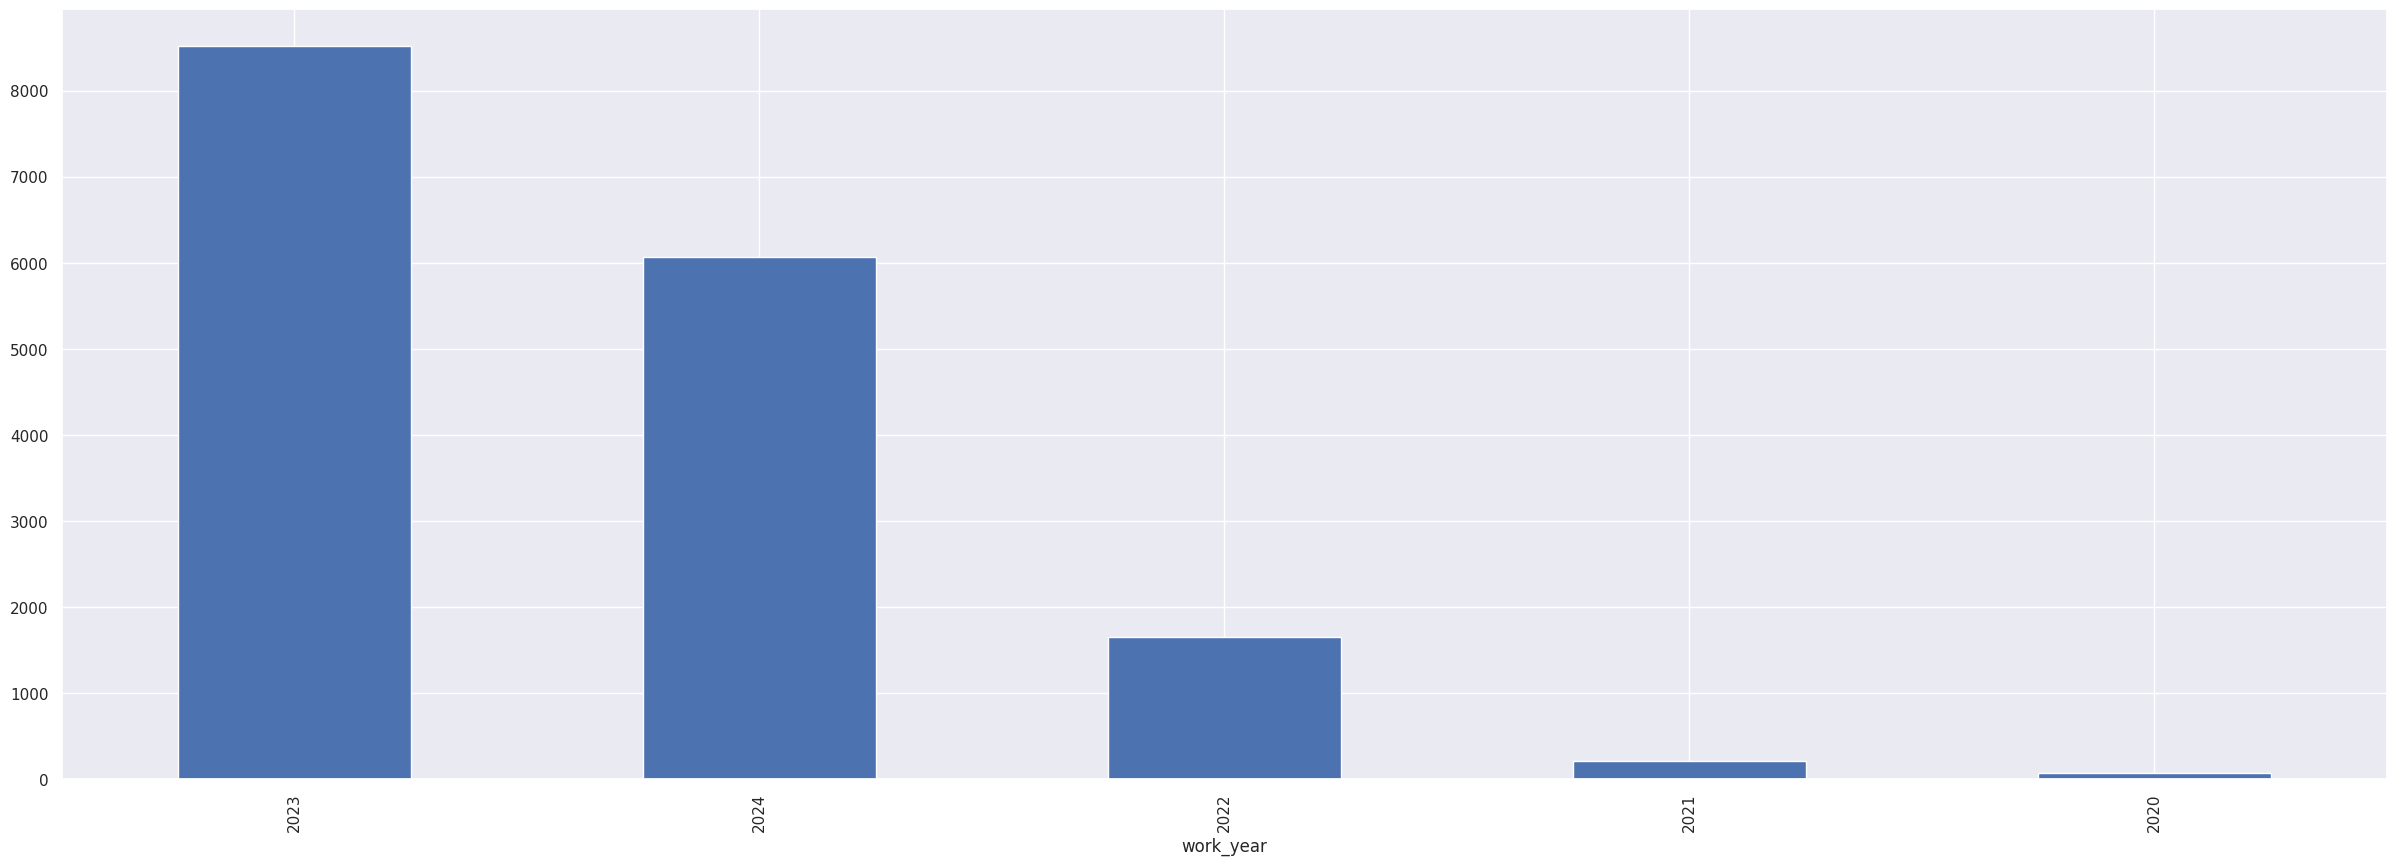

work_year
2023    0.515241
2024    0.366941
2022    0.100097
2021    0.013185
2020    0.004536
Name: count, dtype: float64


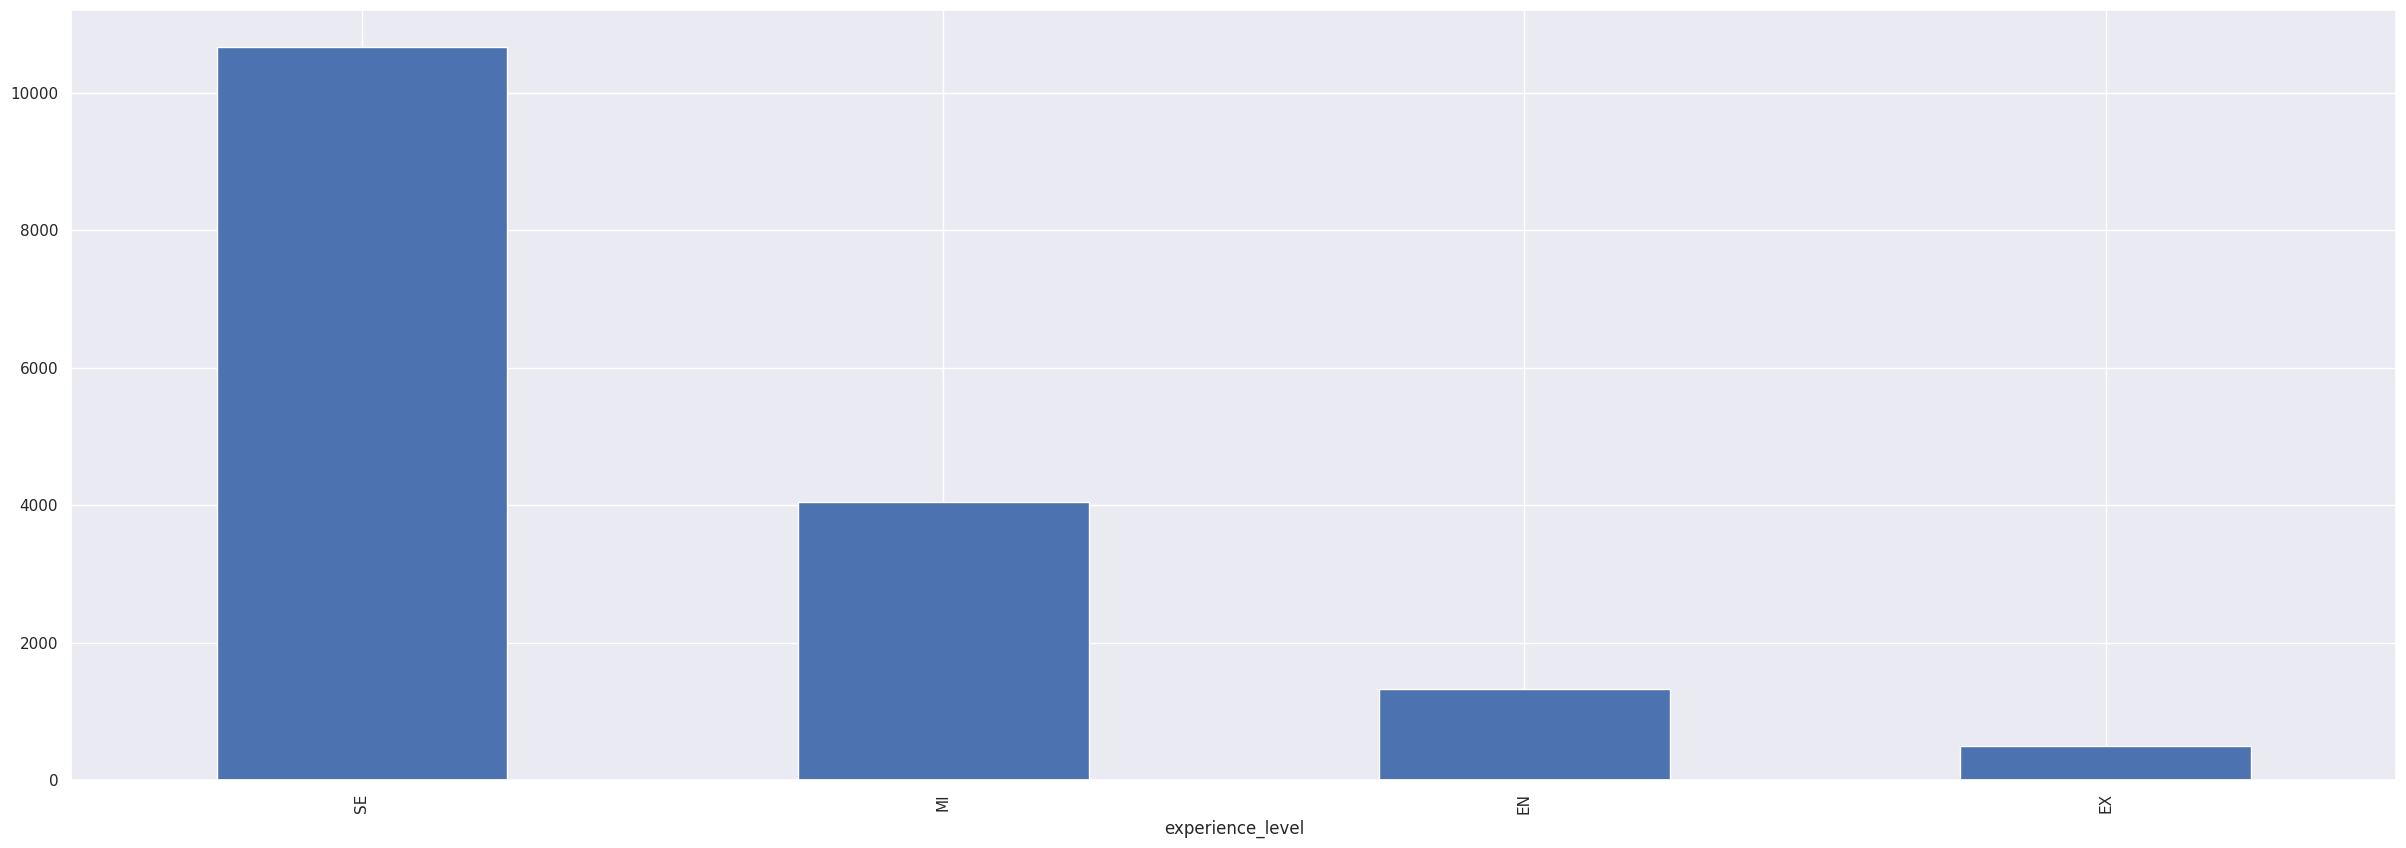

experience_level
SE    0.645337
MI    0.244224
EN    0.080138
EX    0.030301
Name: count, dtype: float64


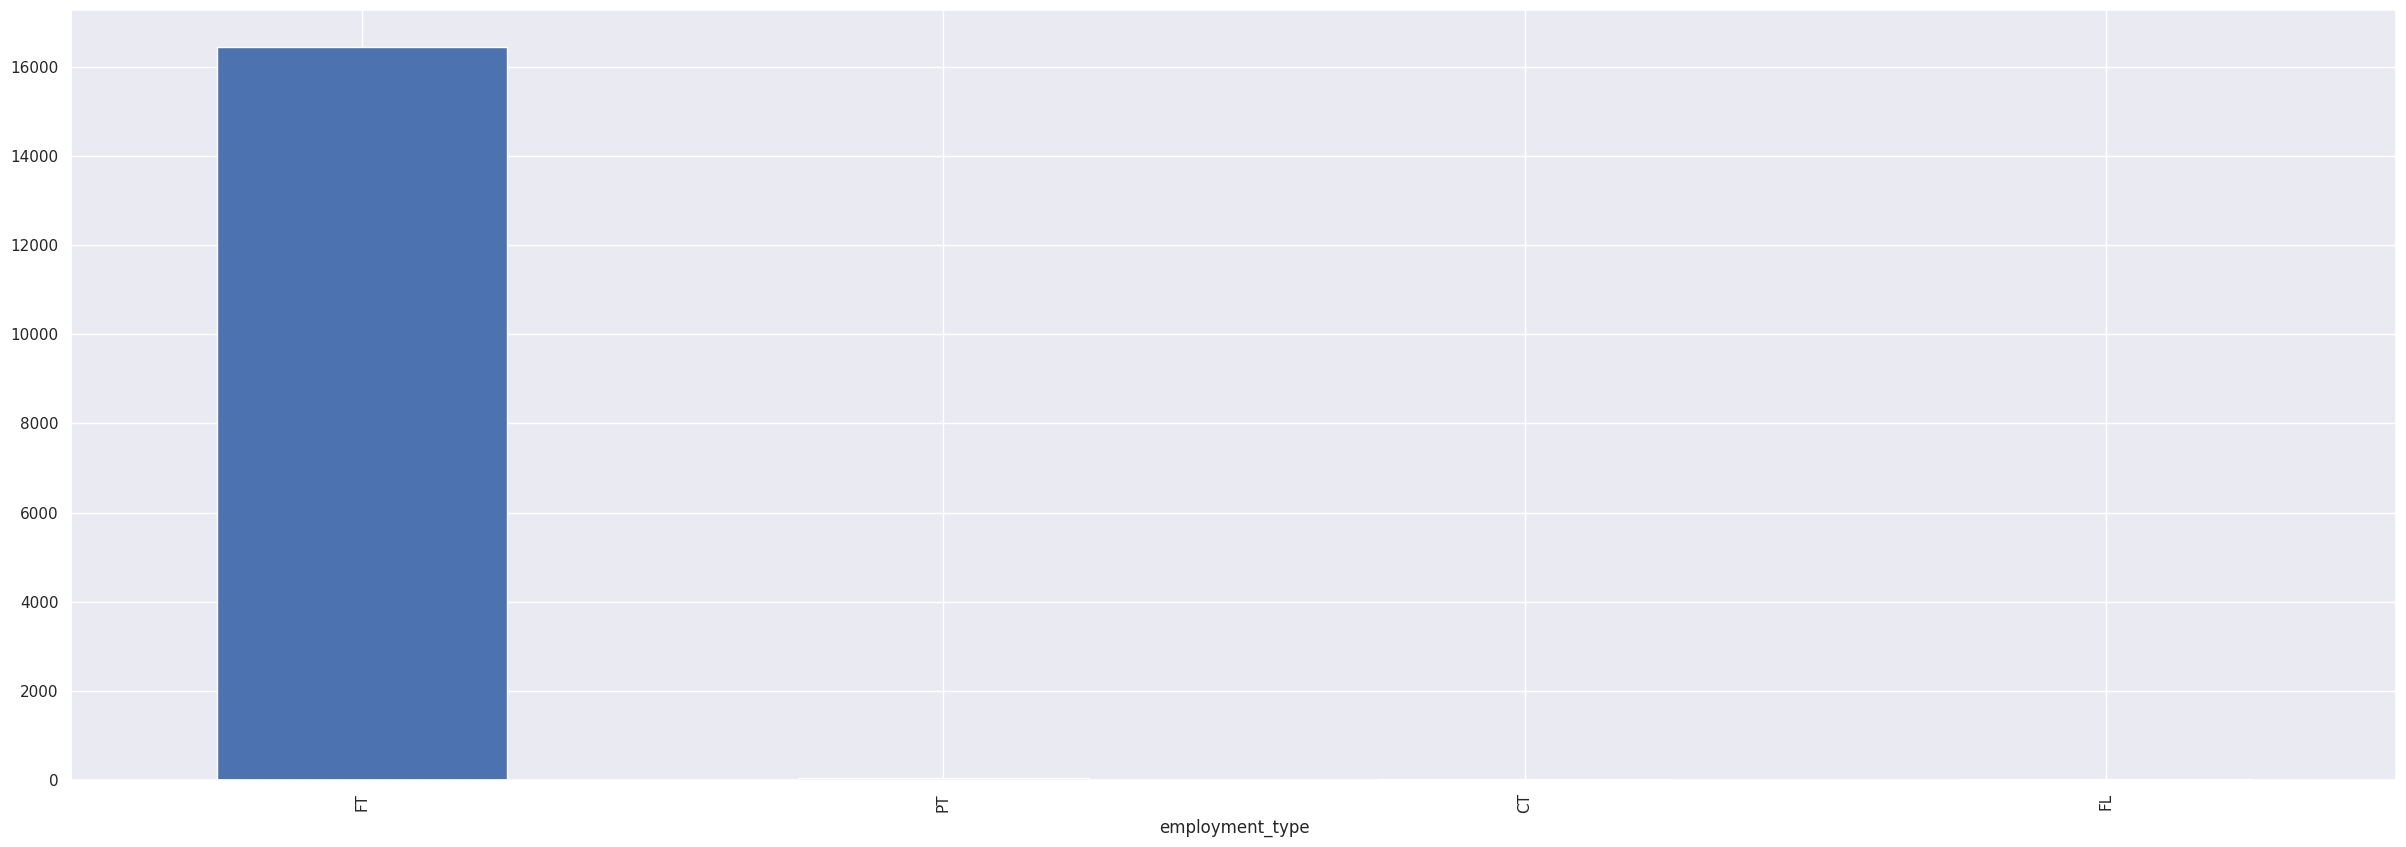

employment_type
FT    0.995161
PT    0.002298
CT    0.001693
FL    0.000847
Name: count, dtype: float64


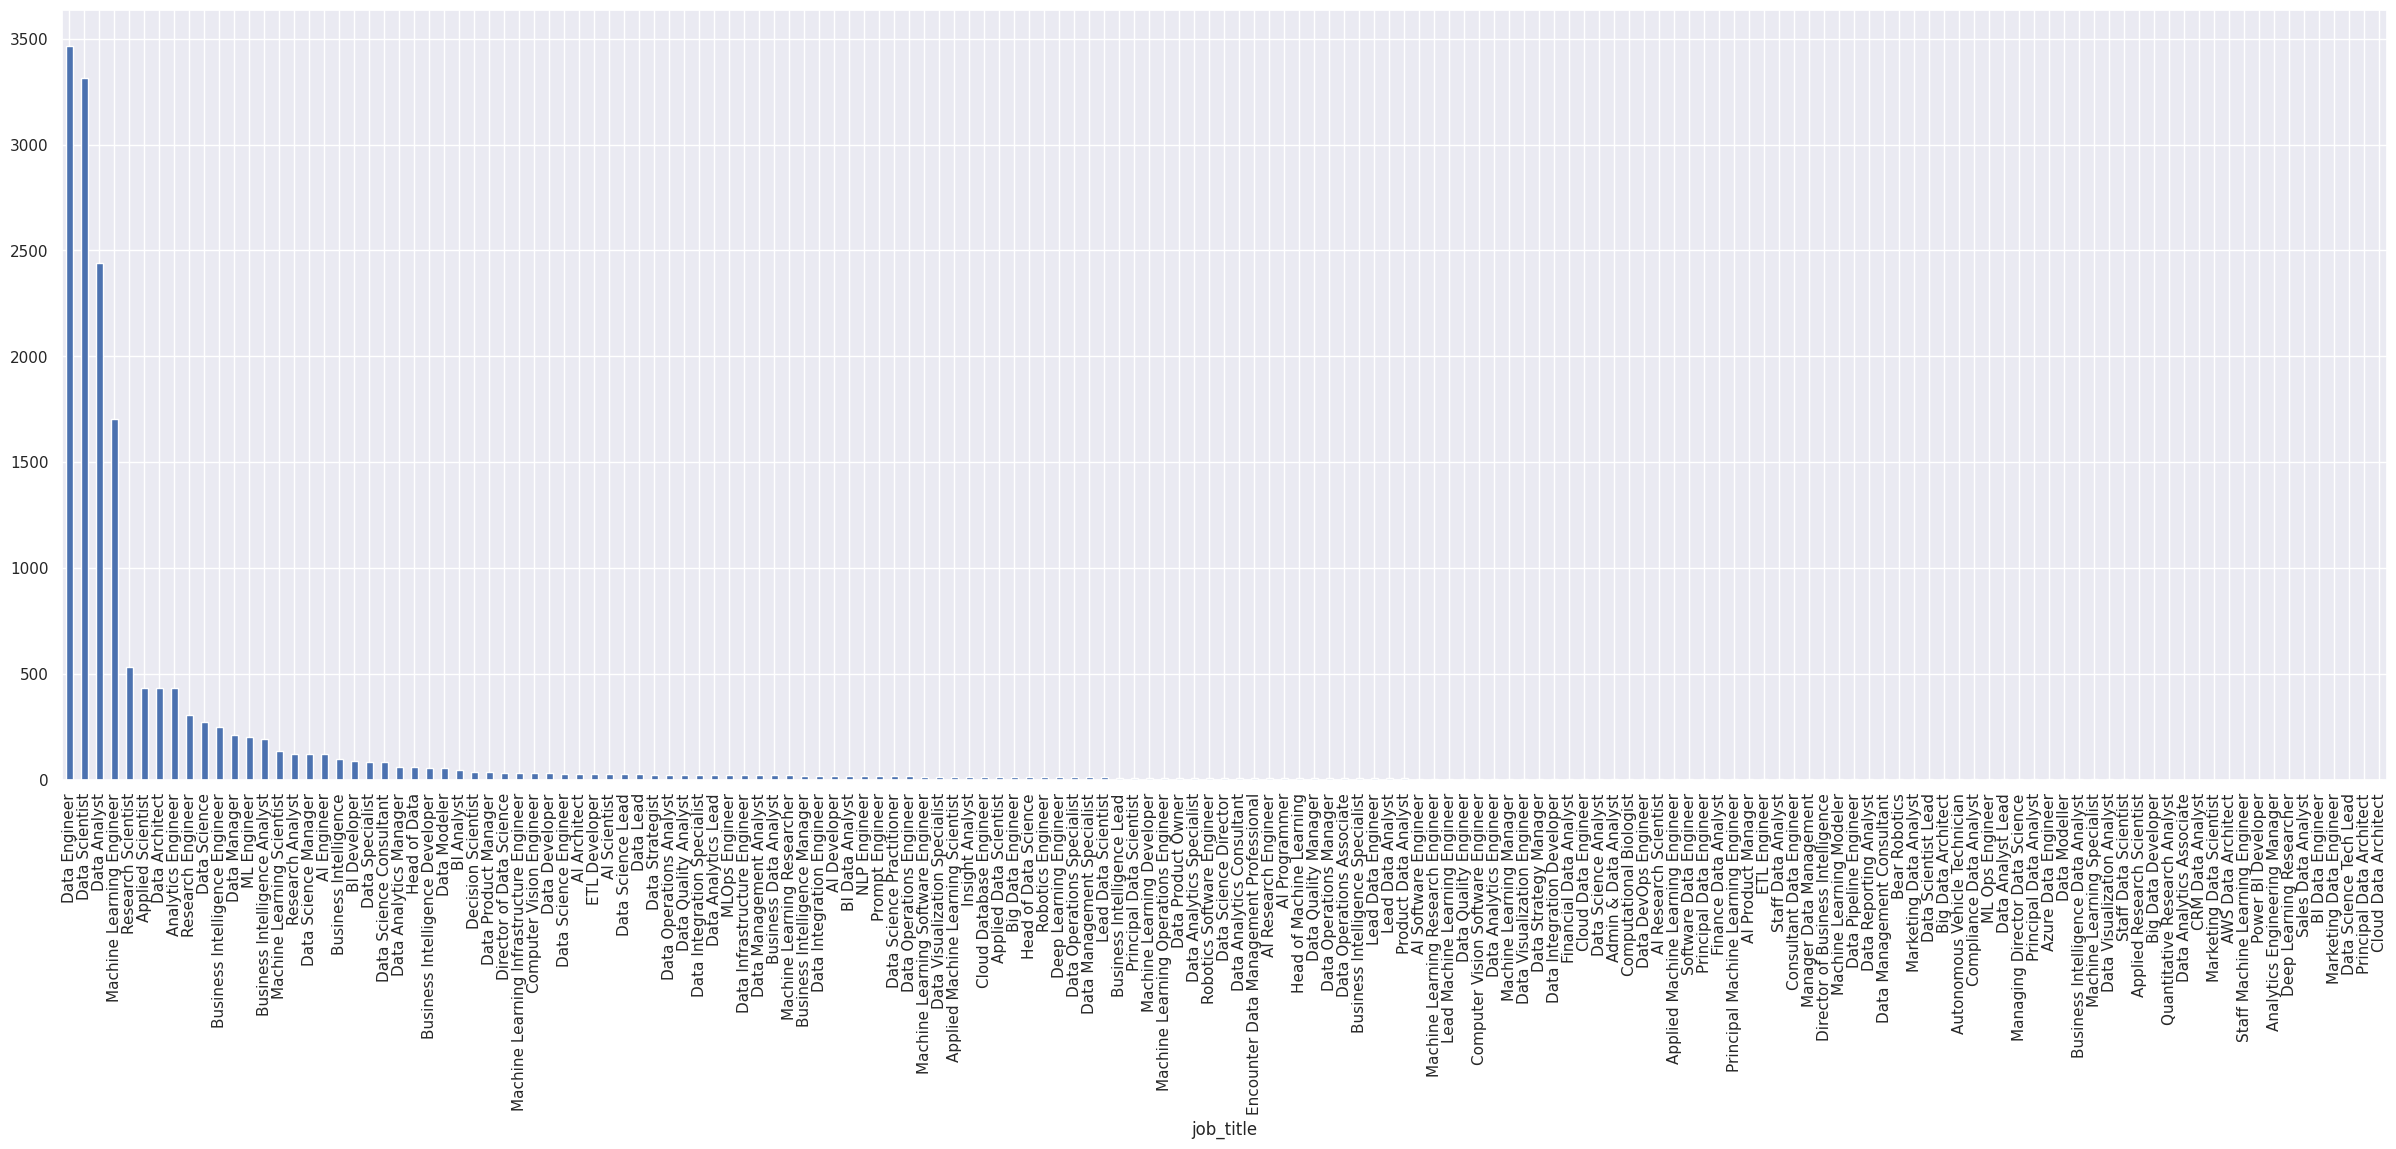

job_title
Data Engineer                0.209508
Data Scientist               0.200435
Data Analyst                 0.147575
Machine Learning Engineer    0.103121
Research Scientist           0.032116
                               ...   
BI Data Engineer             0.000060
Marketing Data Engineer      0.000060
Data Science Tech Lead       0.000060
Principal Data Architect     0.000060
Cloud Data Architect         0.000060
Name: count, Length: 155, dtype: float64


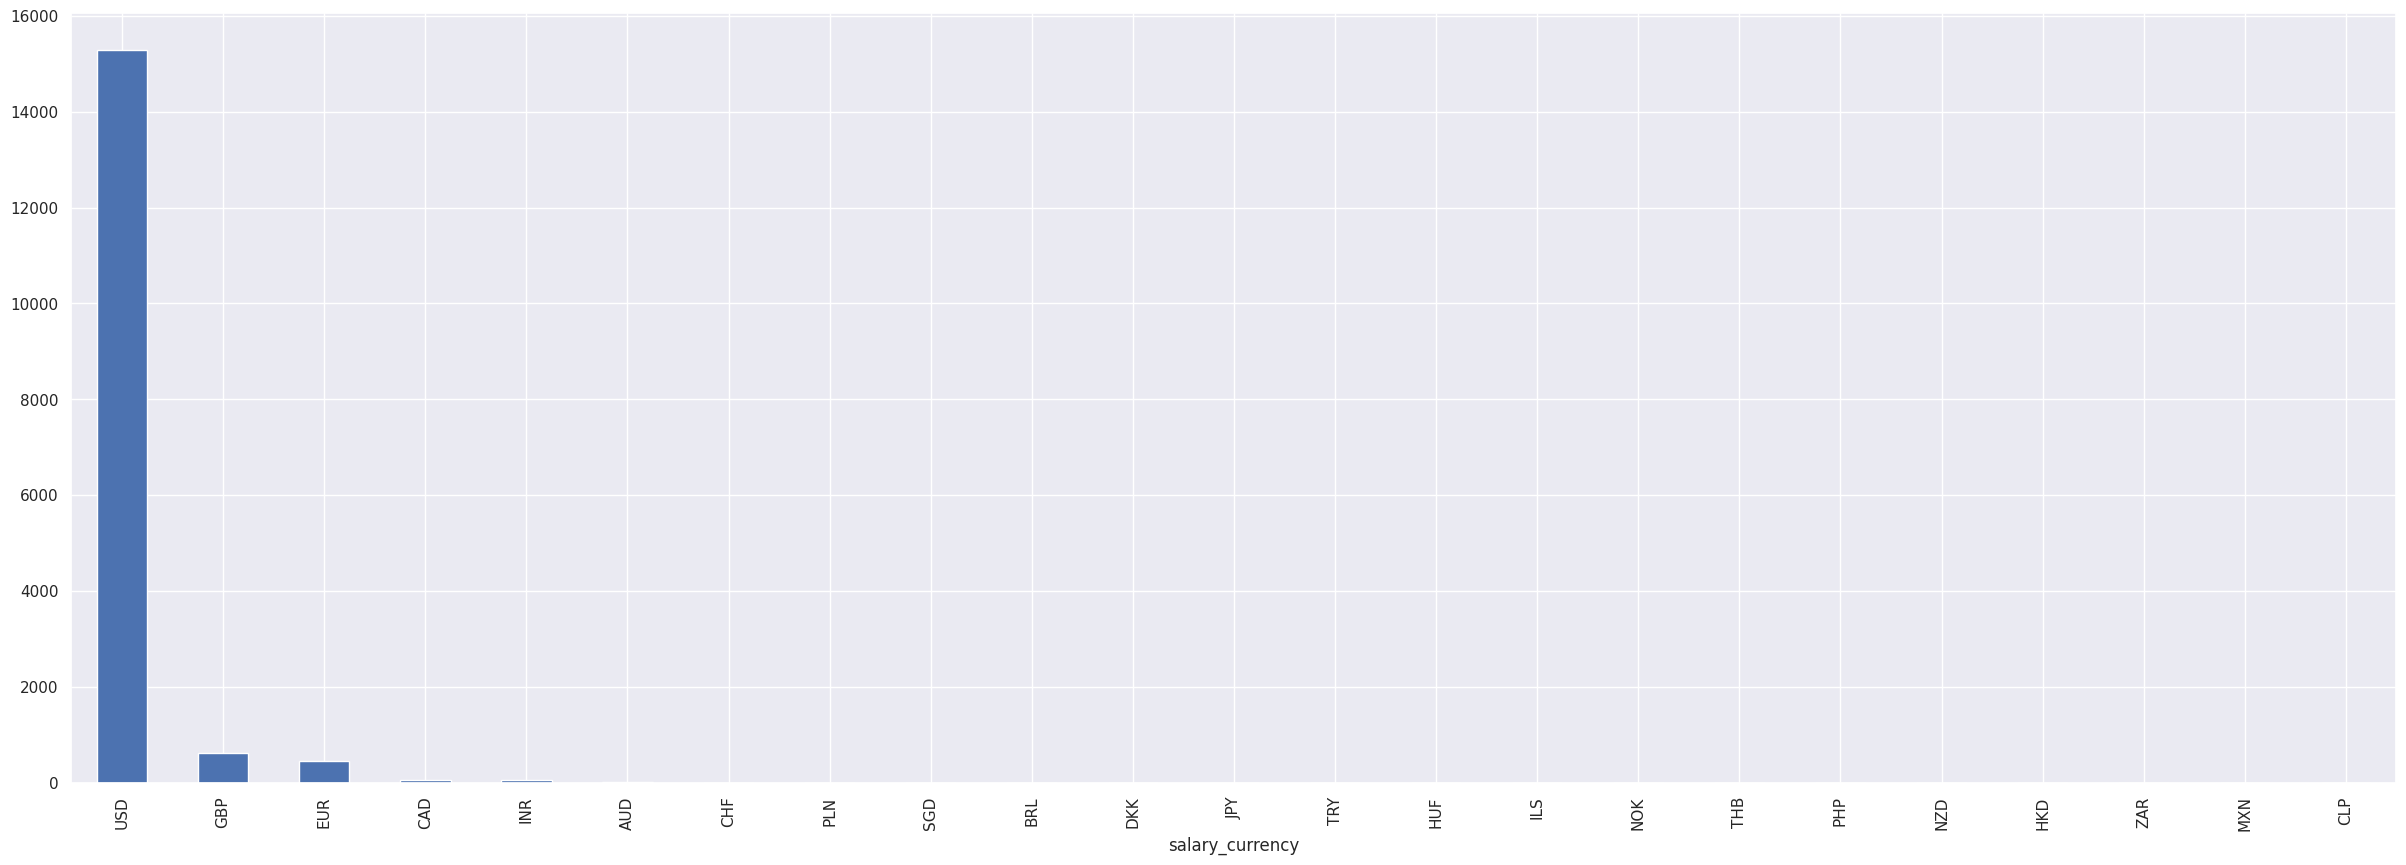

salary_currency
USD    0.925003
GBP    0.037257
EUR    0.027156
CAD    0.003387
INR    0.003326
AUD    0.000726
CHF    0.000484
PLN    0.000423
SGD    0.000363
BRL    0.000302
DKK    0.000242
JPY    0.000242
TRY    0.000181
HUF    0.000181
ILS    0.000121
NOK    0.000121
THB    0.000121
PHP    0.000060
NZD    0.000060
HKD    0.000060
ZAR    0.000060
MXN    0.000060
CLP    0.000060
Name: count, dtype: float64


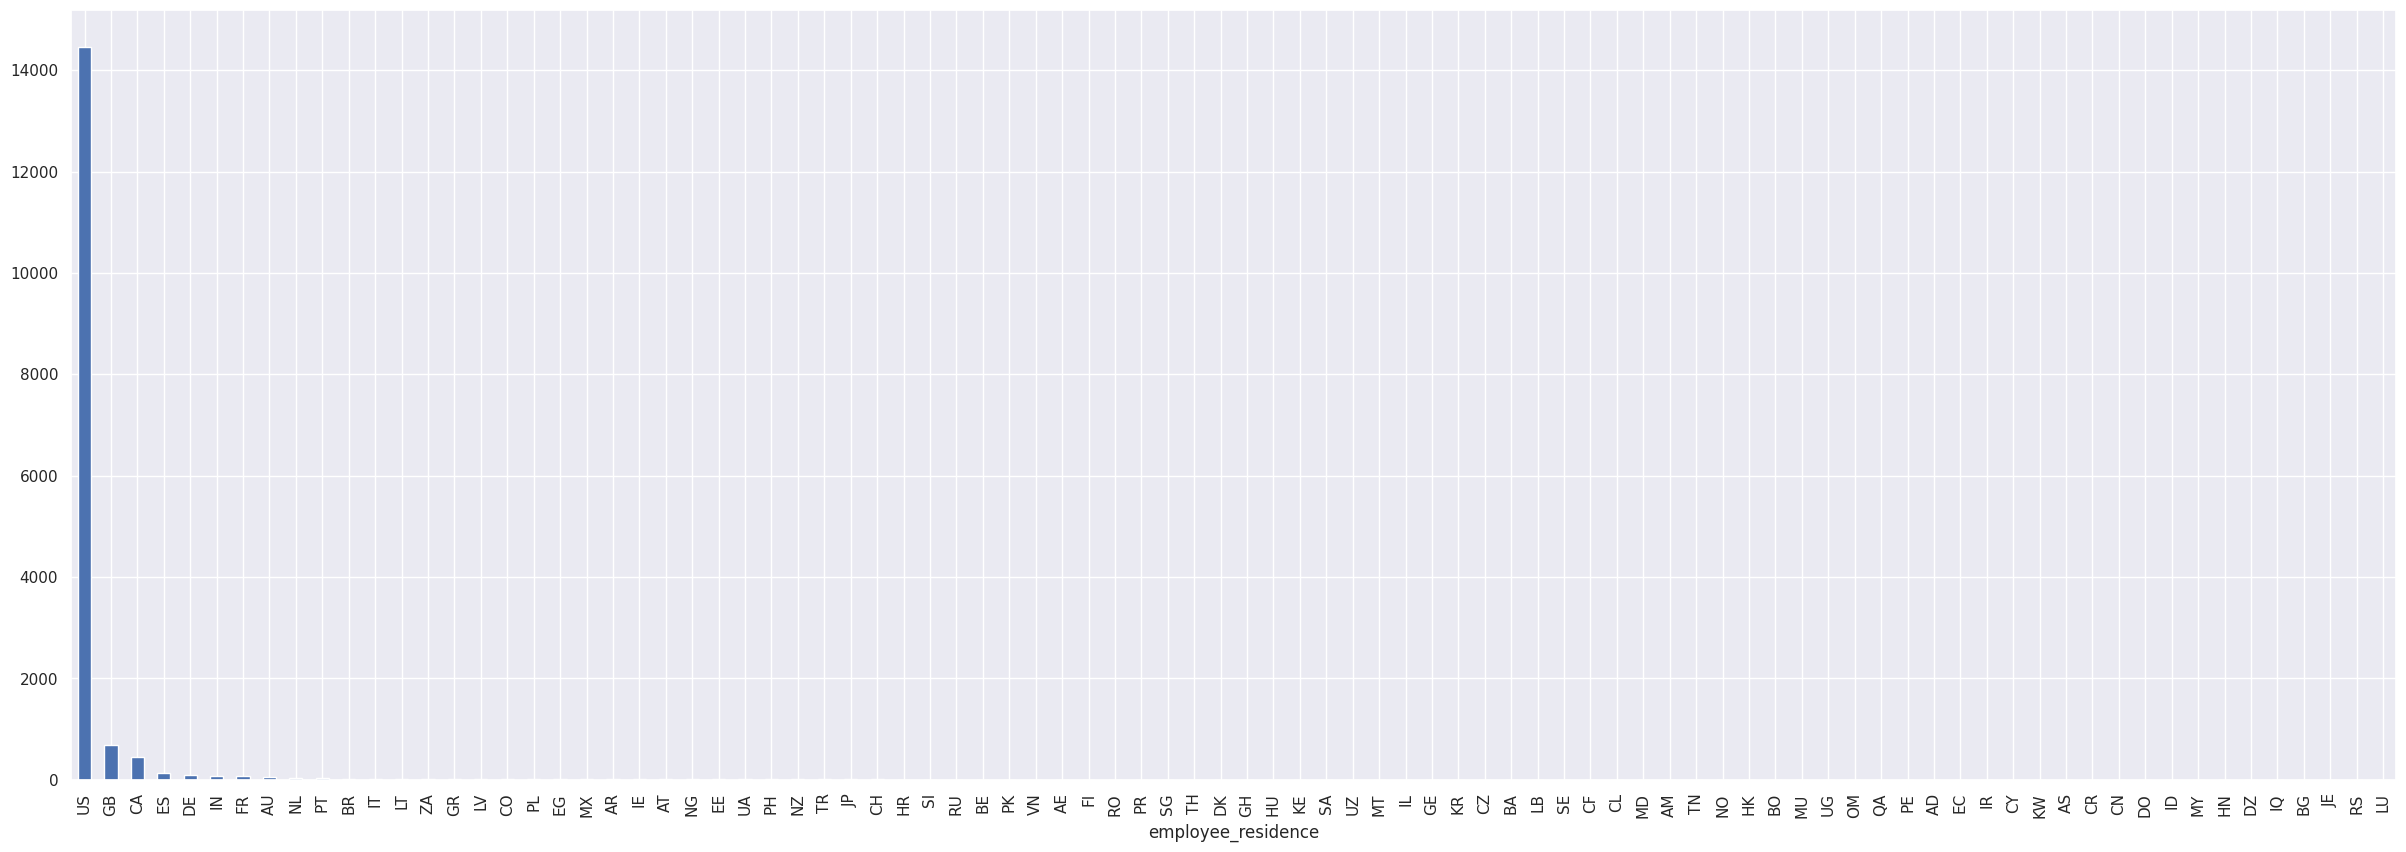

employee_residence
US    0.874985
GB    0.041490
CA    0.027398
ES    0.008286
DE    0.005927
        ...   
IQ    0.000060
BG    0.000060
JE    0.000060
RS    0.000060
LU    0.000060
Name: count, Length: 88, dtype: float64


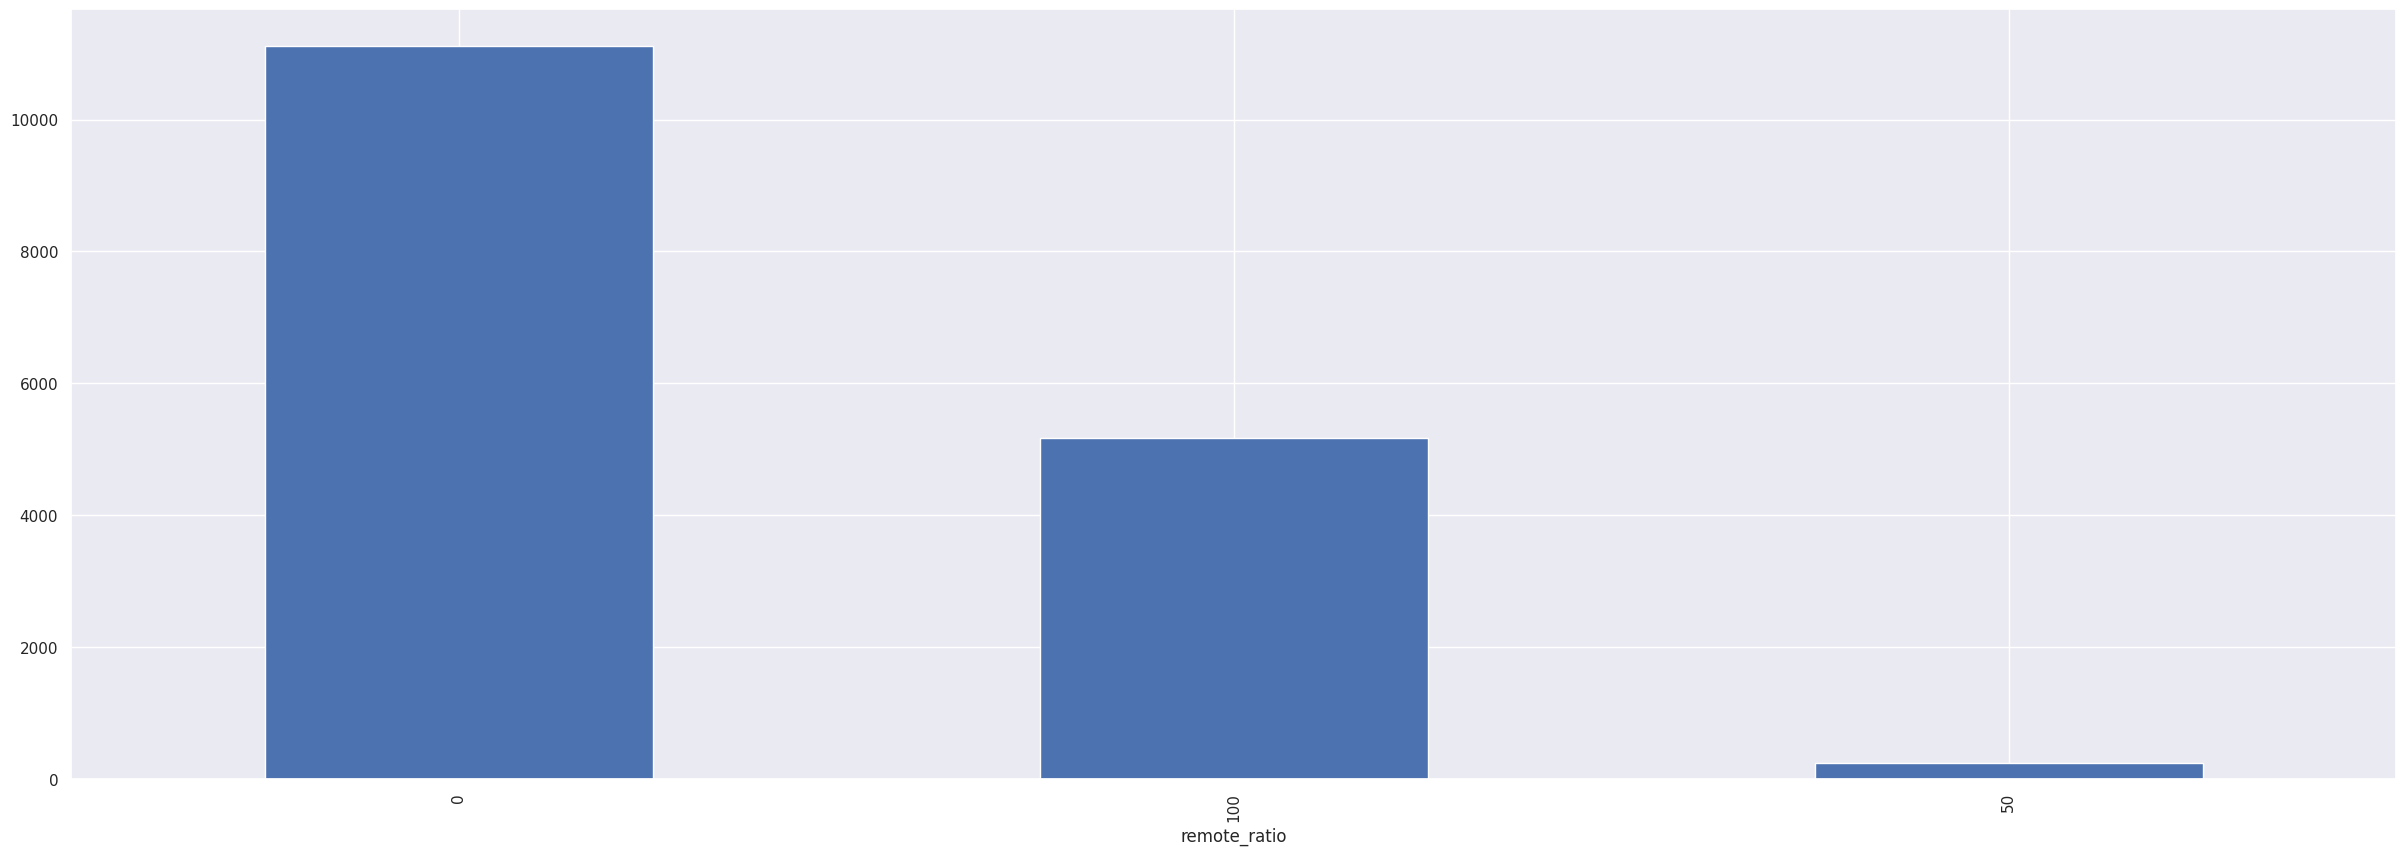

remote_ratio
0      0.672433
100    0.312508
50     0.015060
Name: count, dtype: float64


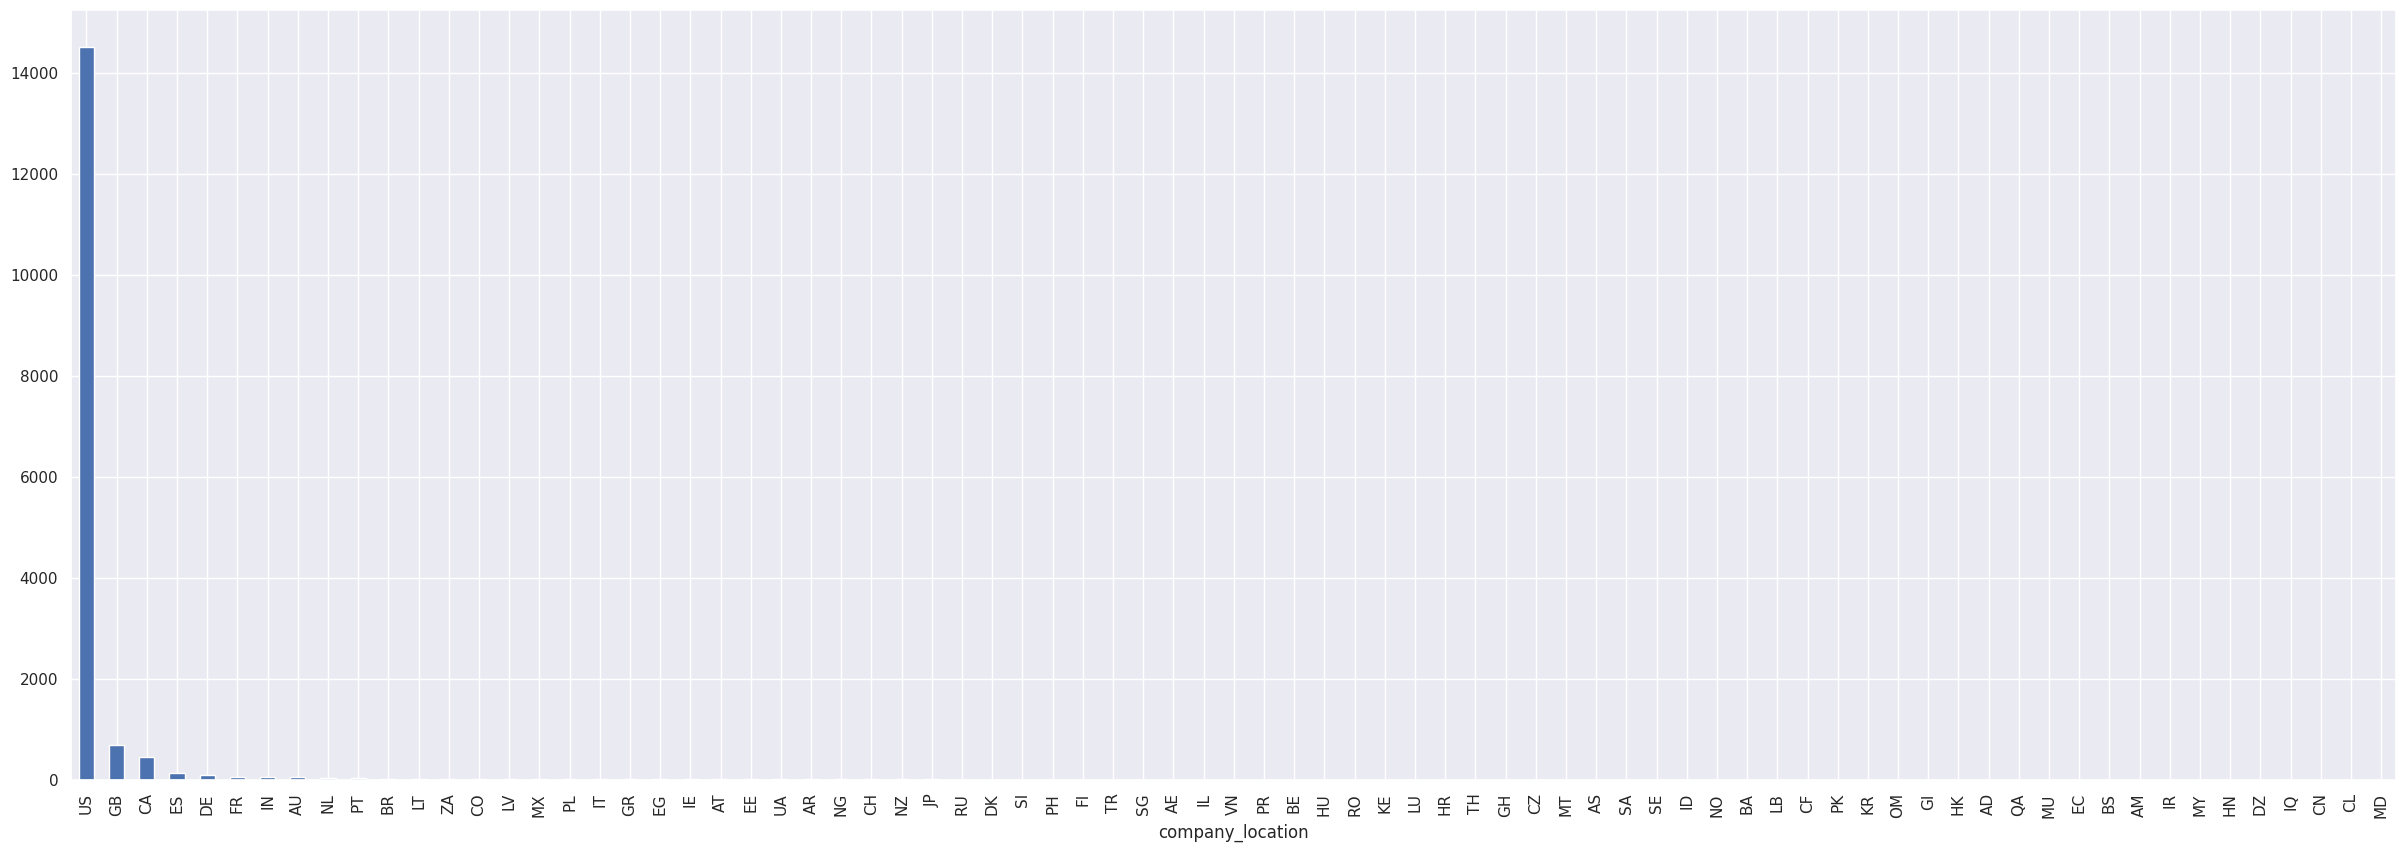

company_location
US    0.878069
GB    0.041974
CA    0.027519
ES    0.008044
DE    0.006351
        ...   
DZ    0.000060
IQ    0.000060
CN    0.000060
CL    0.000060
MD    0.000060
Name: count, Length: 77, dtype: float64


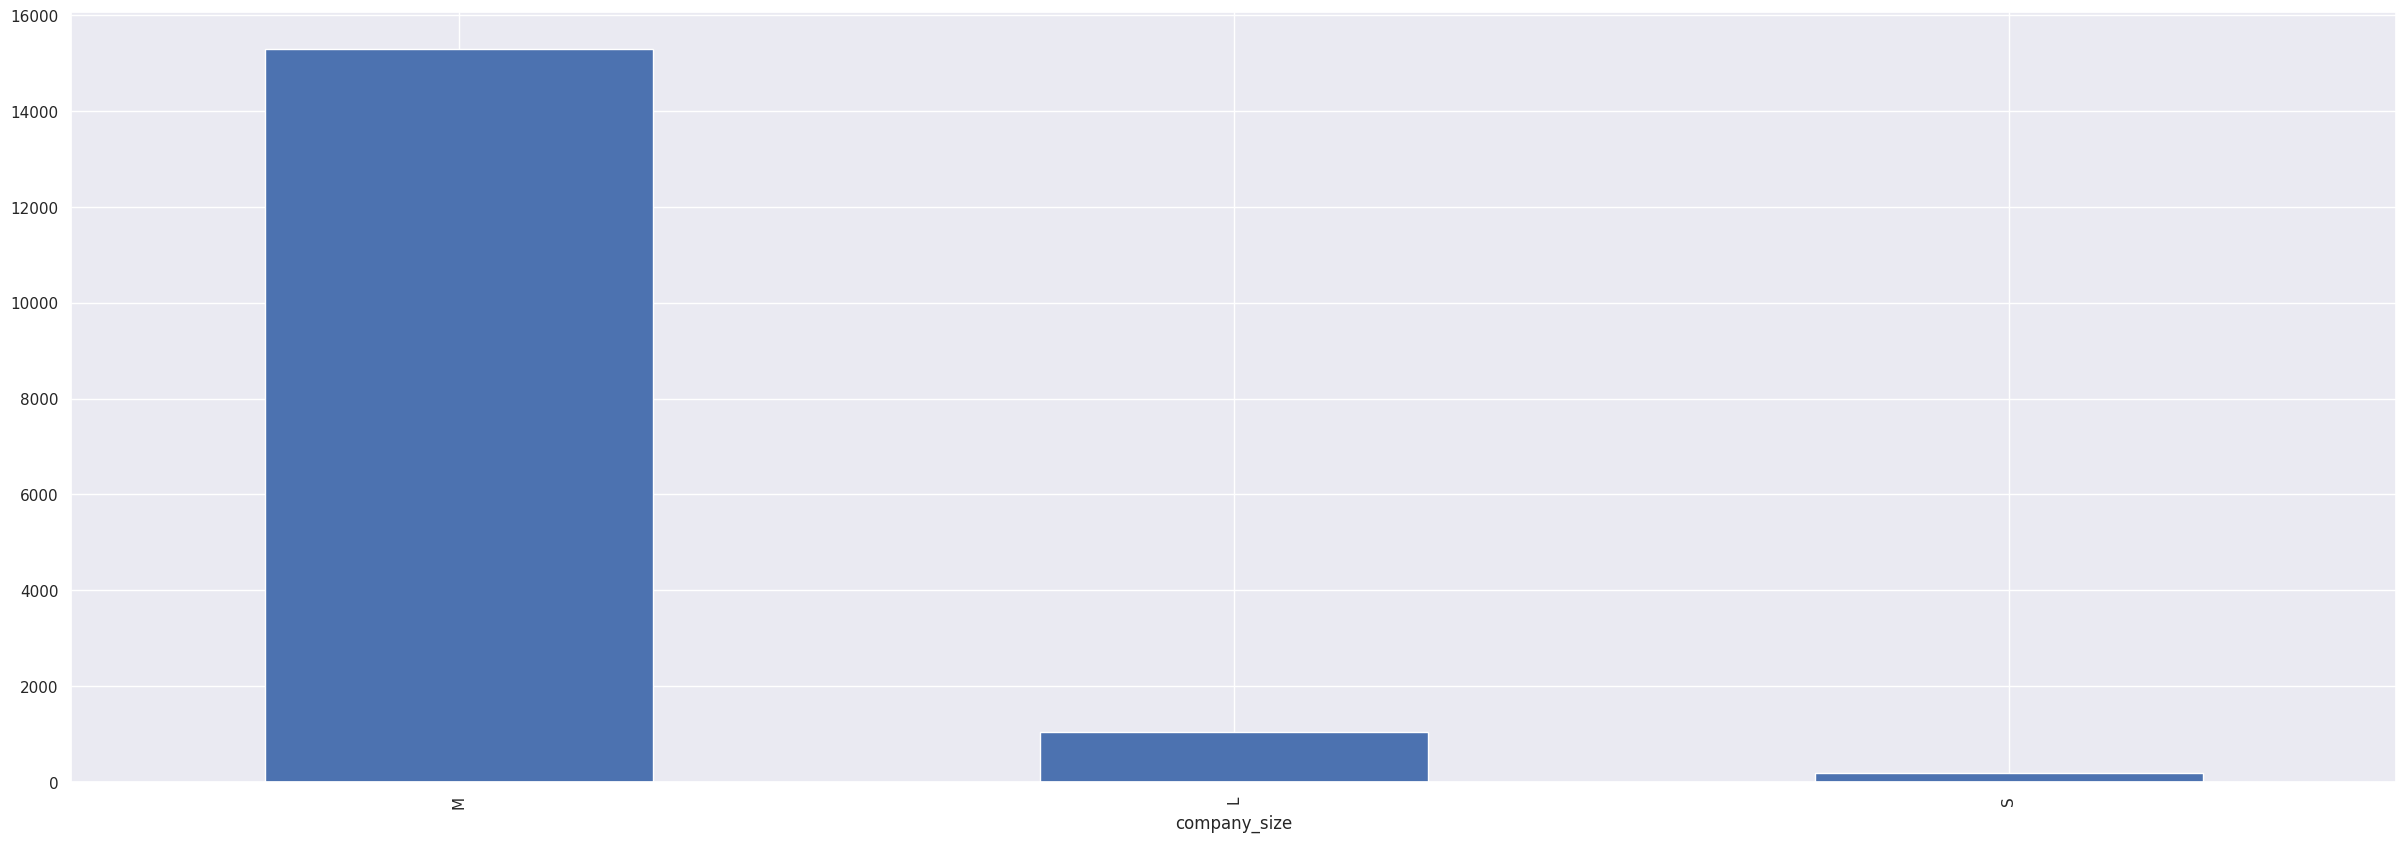

company_size
M    0.925729
L    0.062901
S    0.011371
Name: count, dtype: float64


In [ ]:
def countVariable(df,variable,plot=True,prints=True):
  plt.figure(figsize=(30,10))
  data = df[variable].value_counts()
  if plot:
    data.plot(kind="bar")
    plt.show()
  if prints: print(data.sort_values(ascending=False)/len(df))
  return data

for i in categoricalVariables:
  countVariable(df,i)

Plottin the salary depending on each categorical variable, in order to see if we have different salary value depending on other features. This can be helpful to give signs of correlation between the salary and the categorical values.

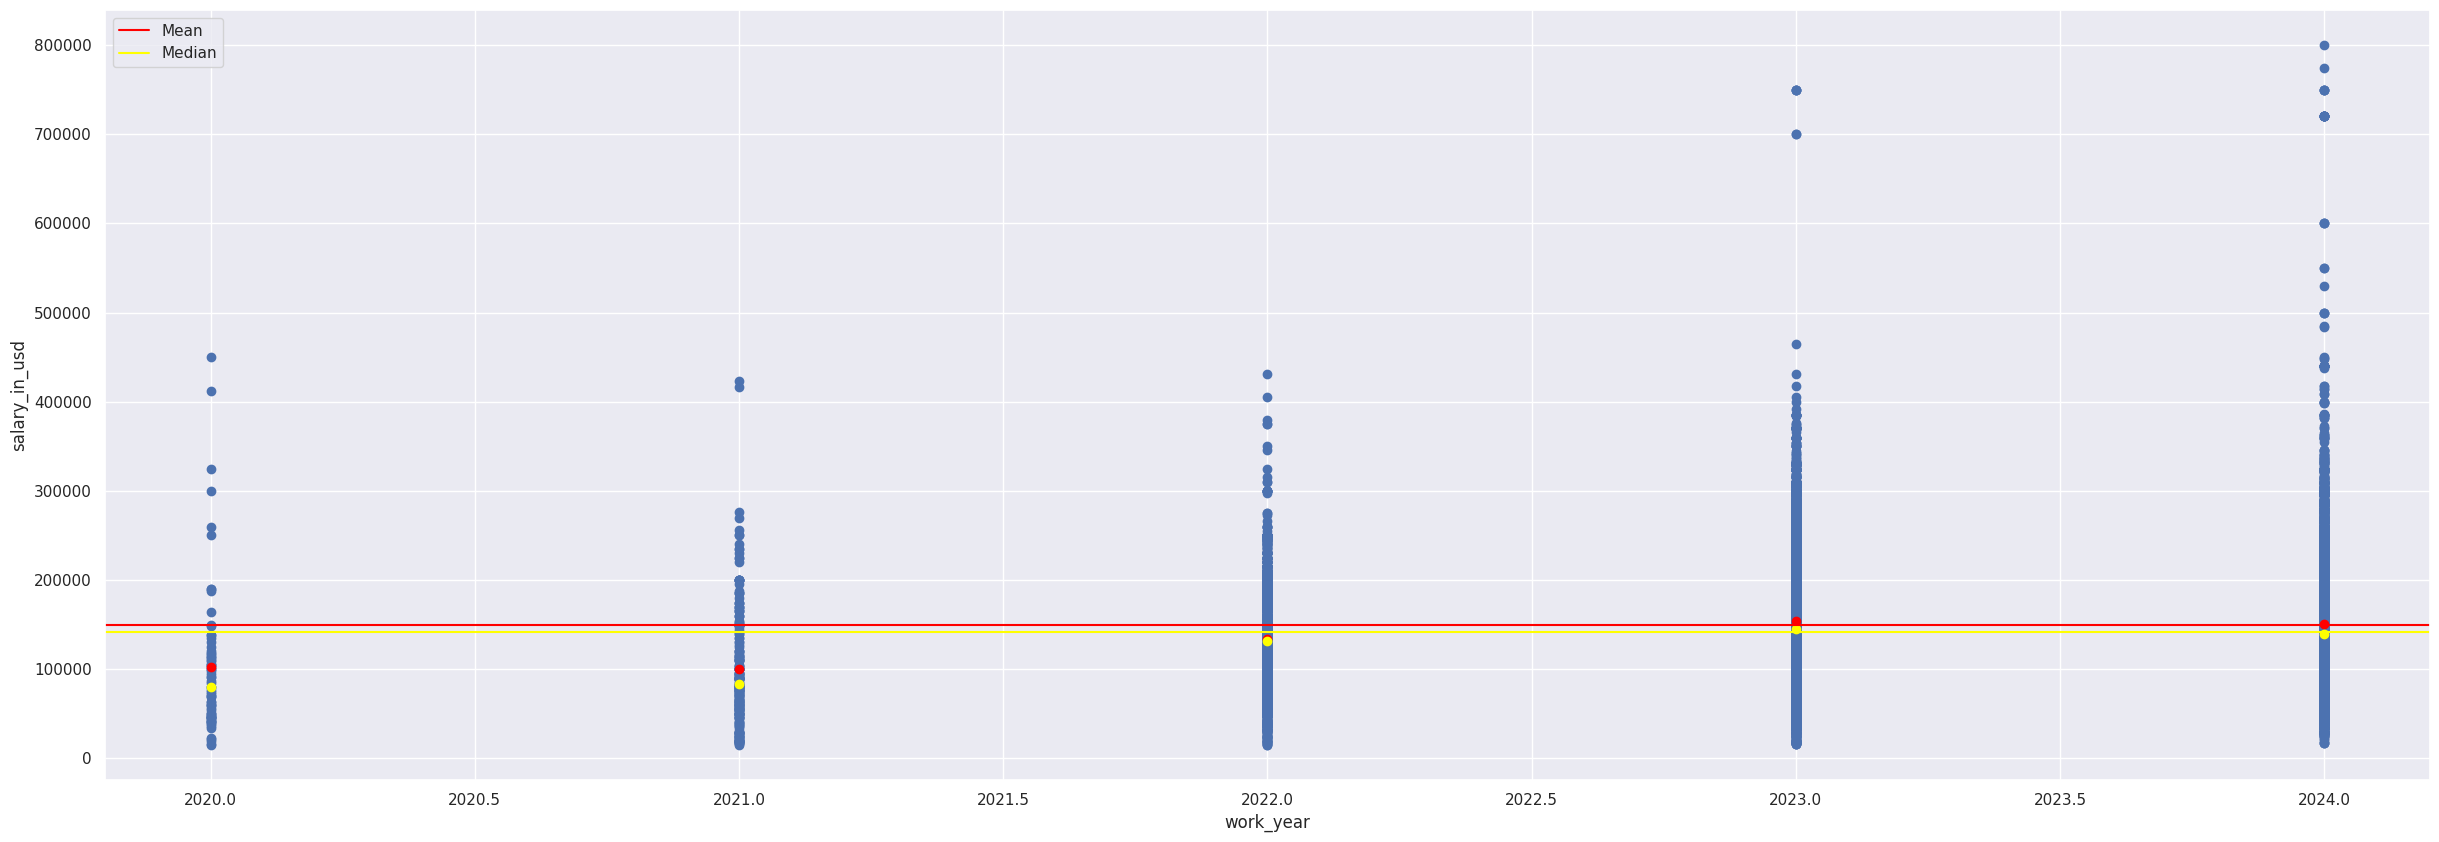

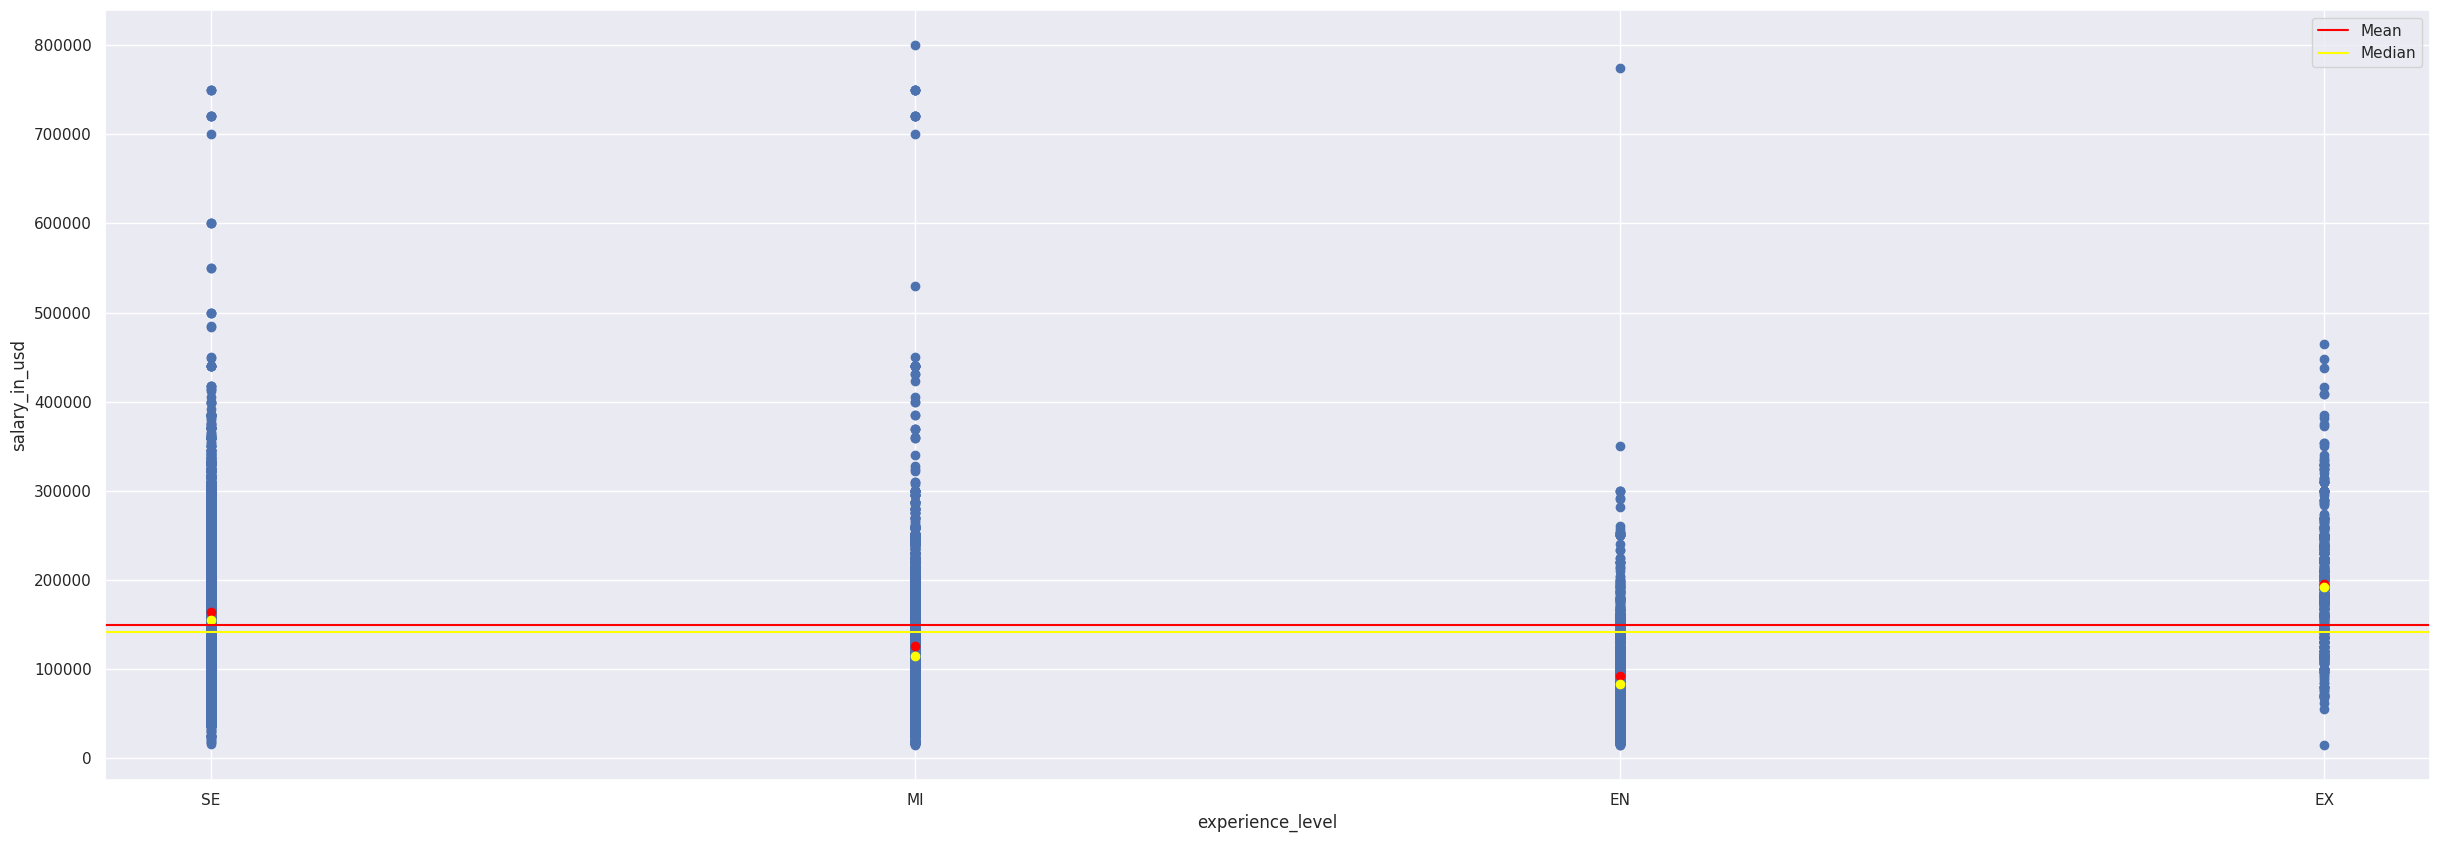

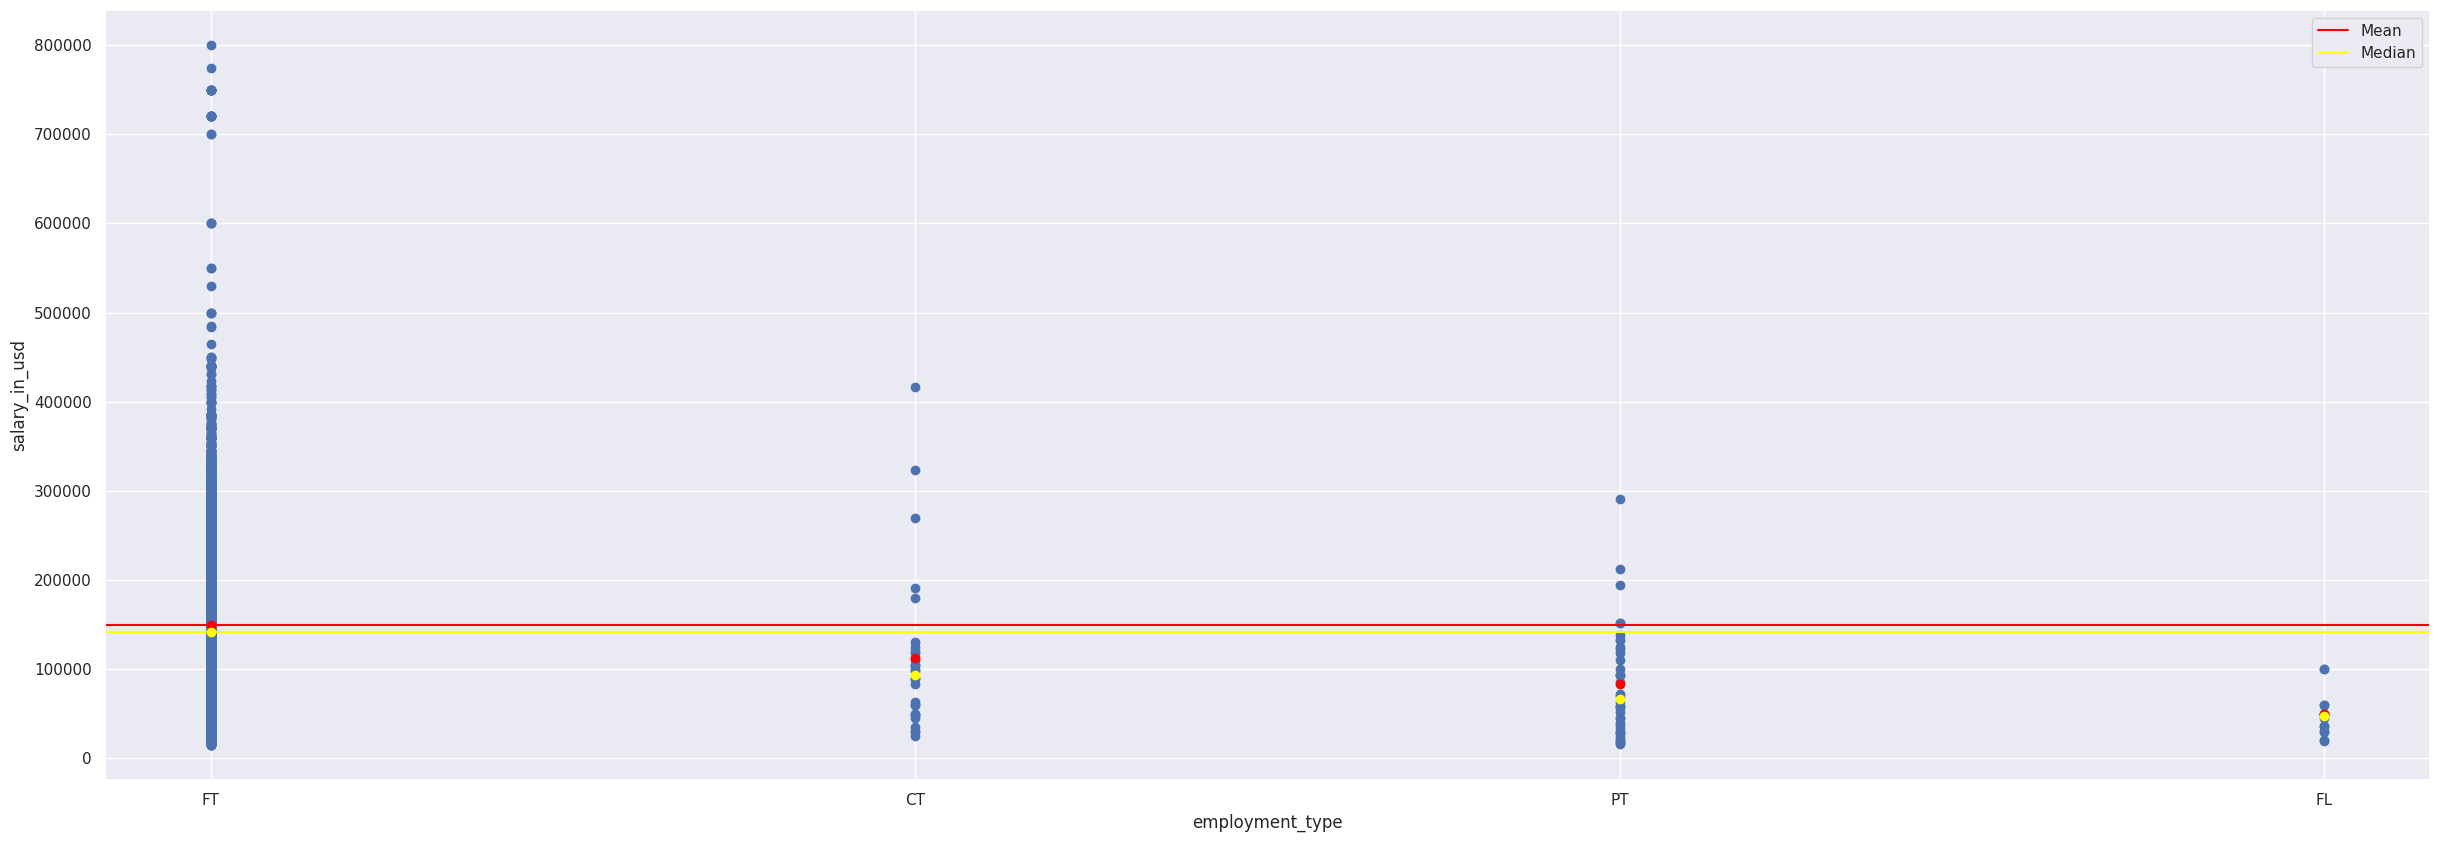

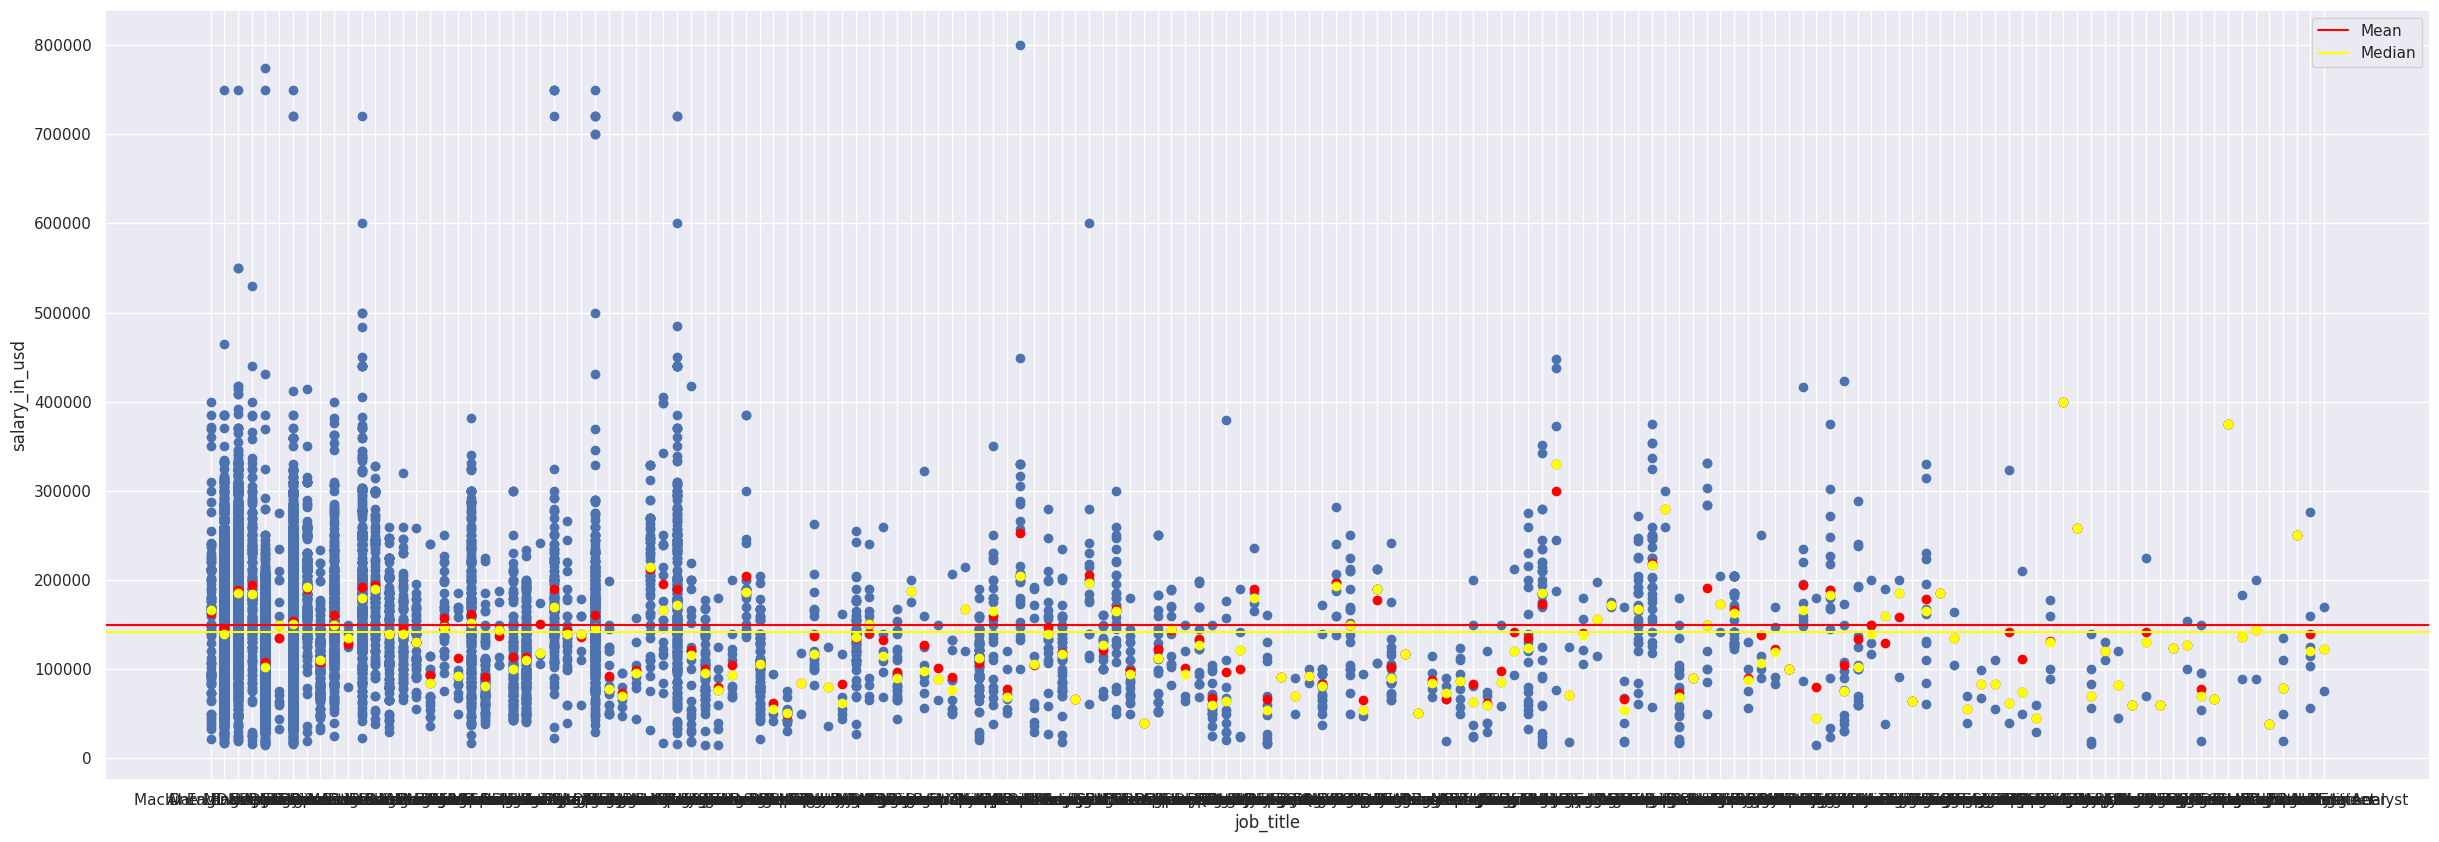

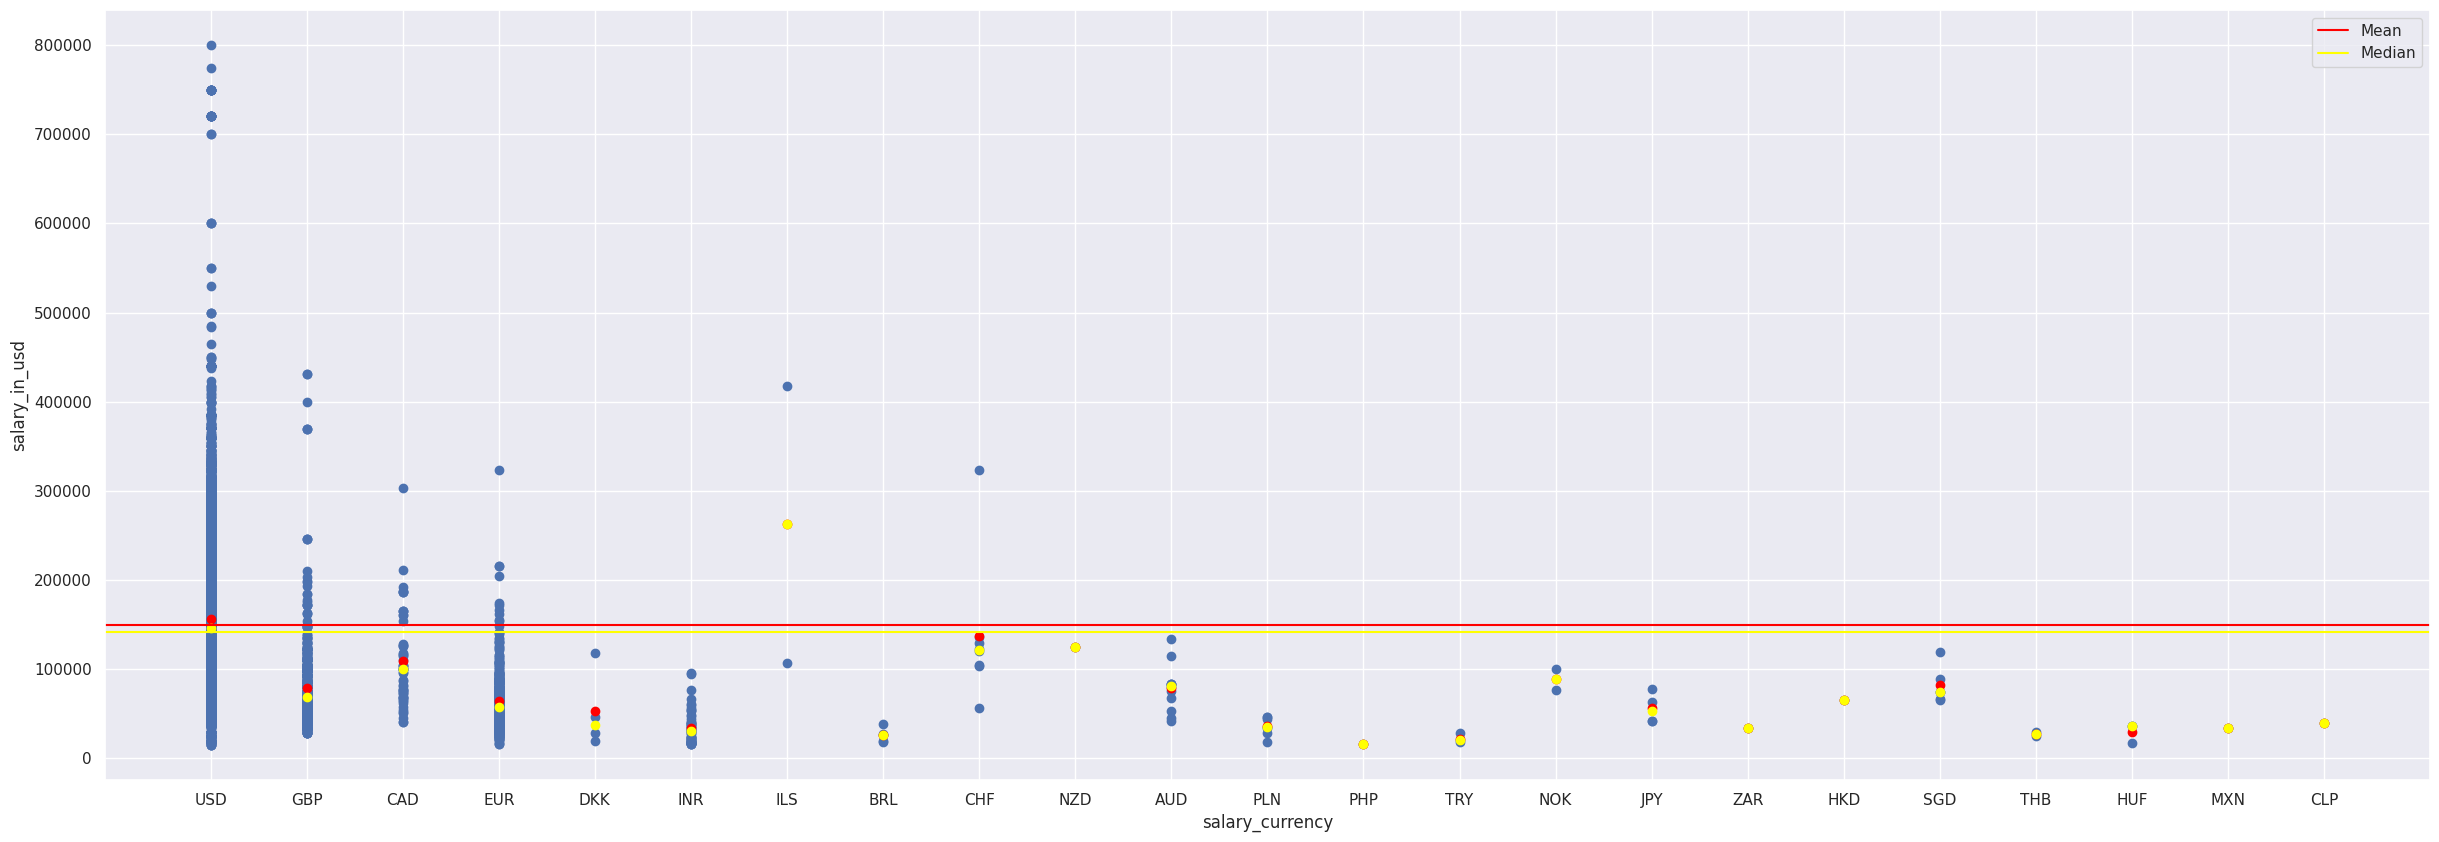

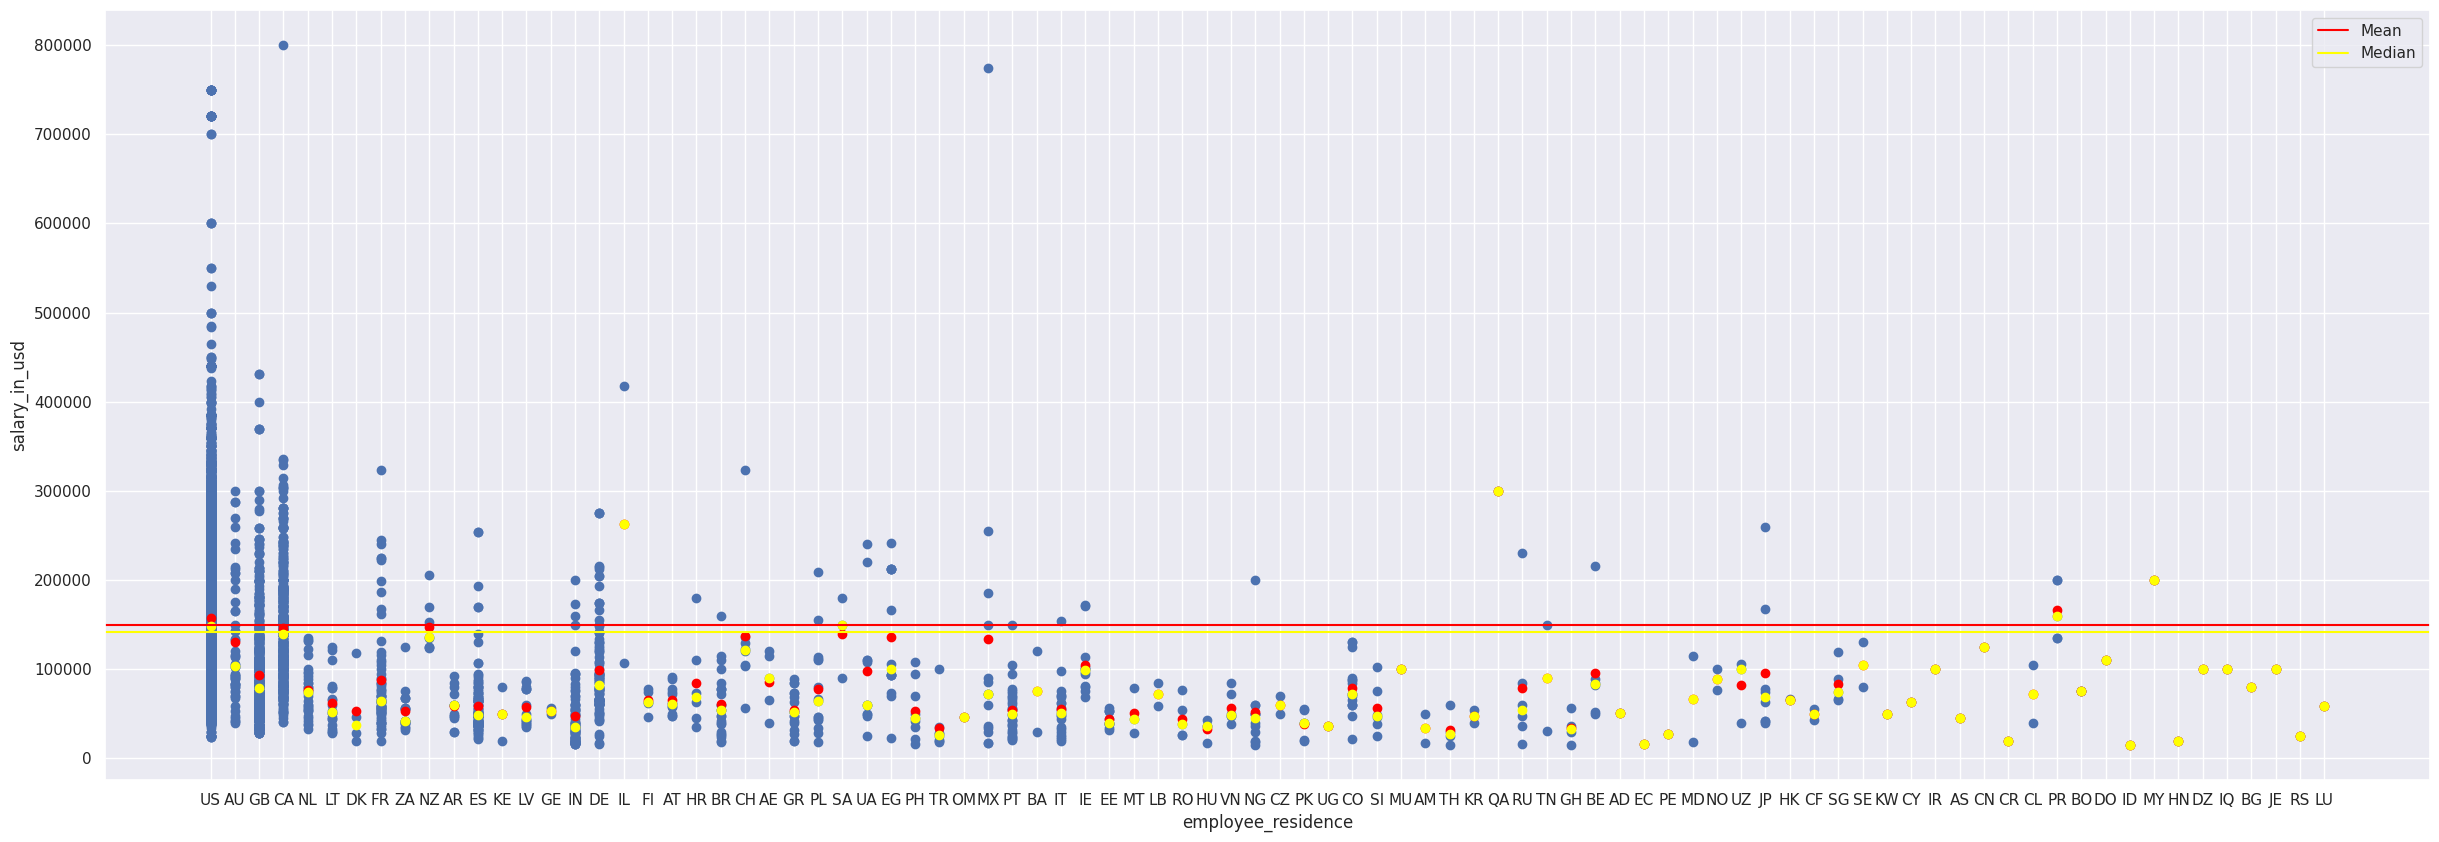

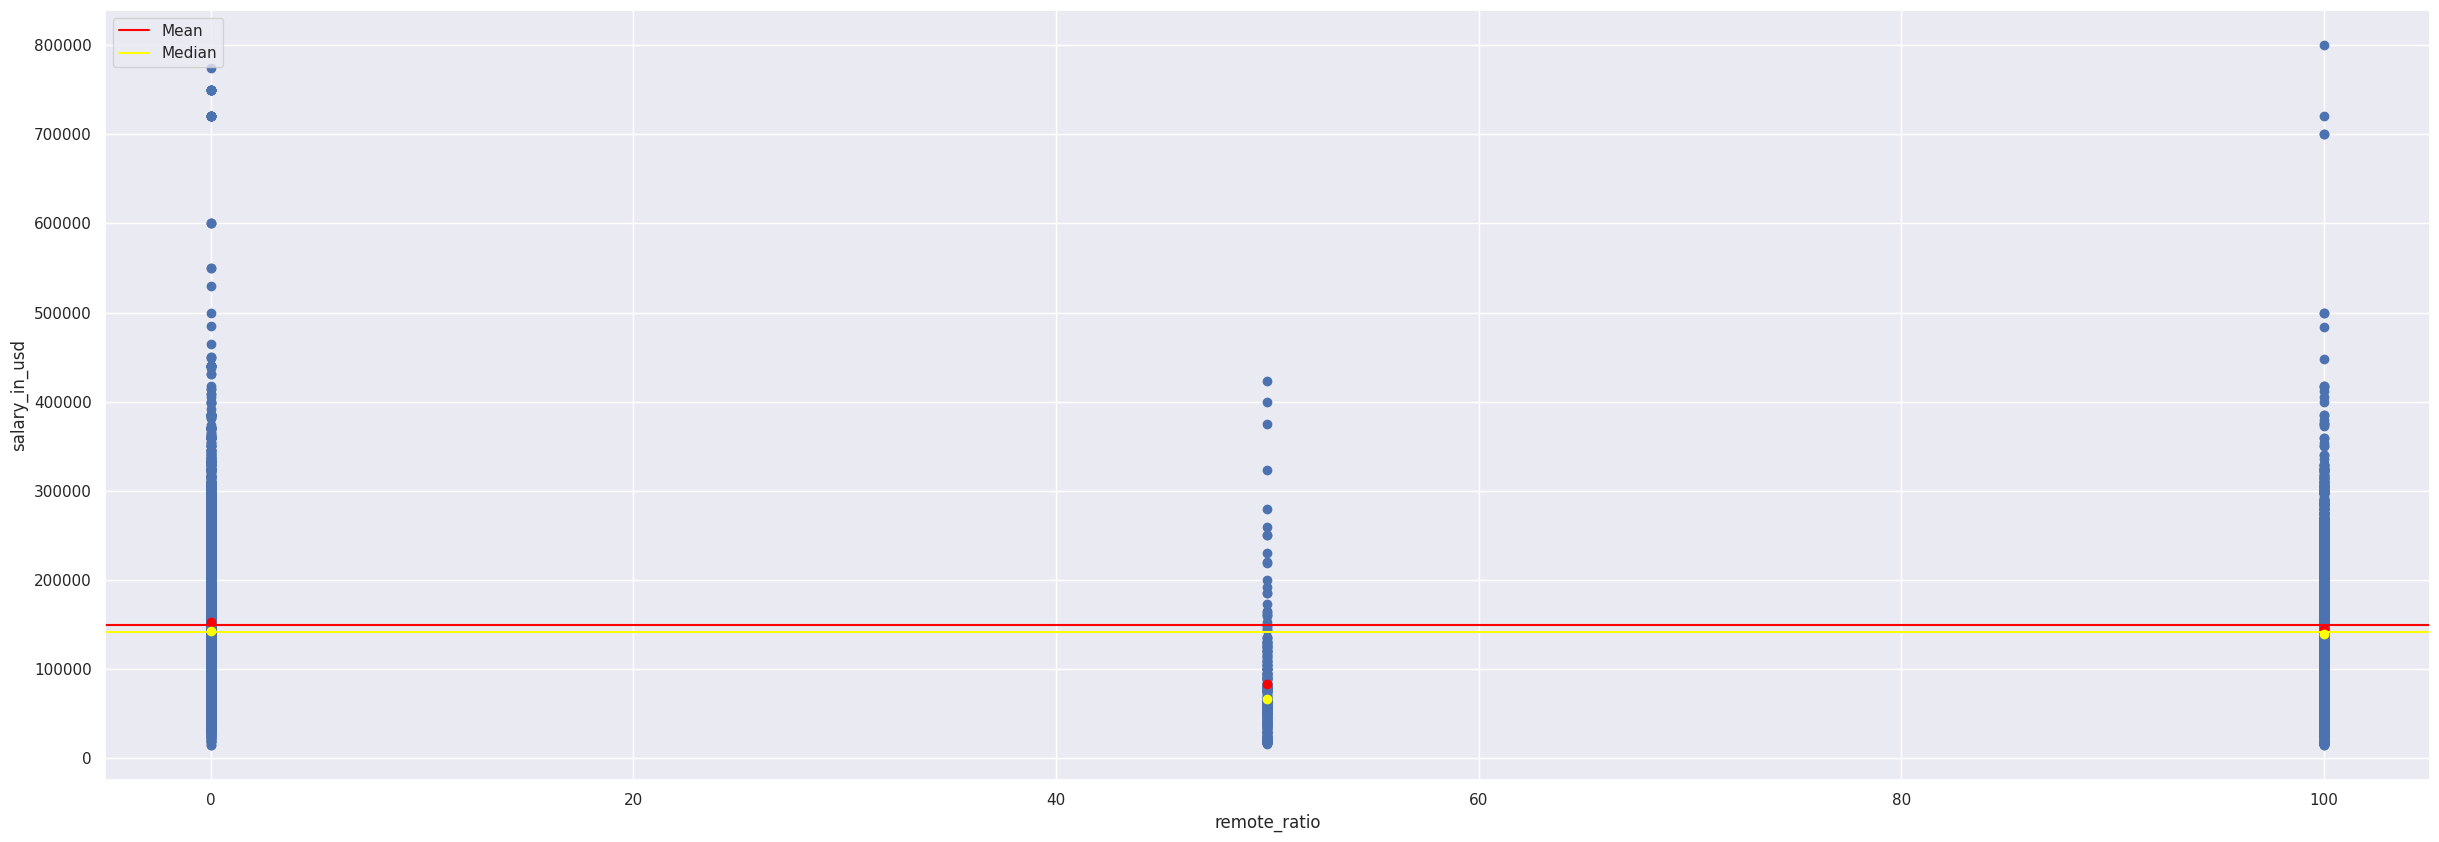

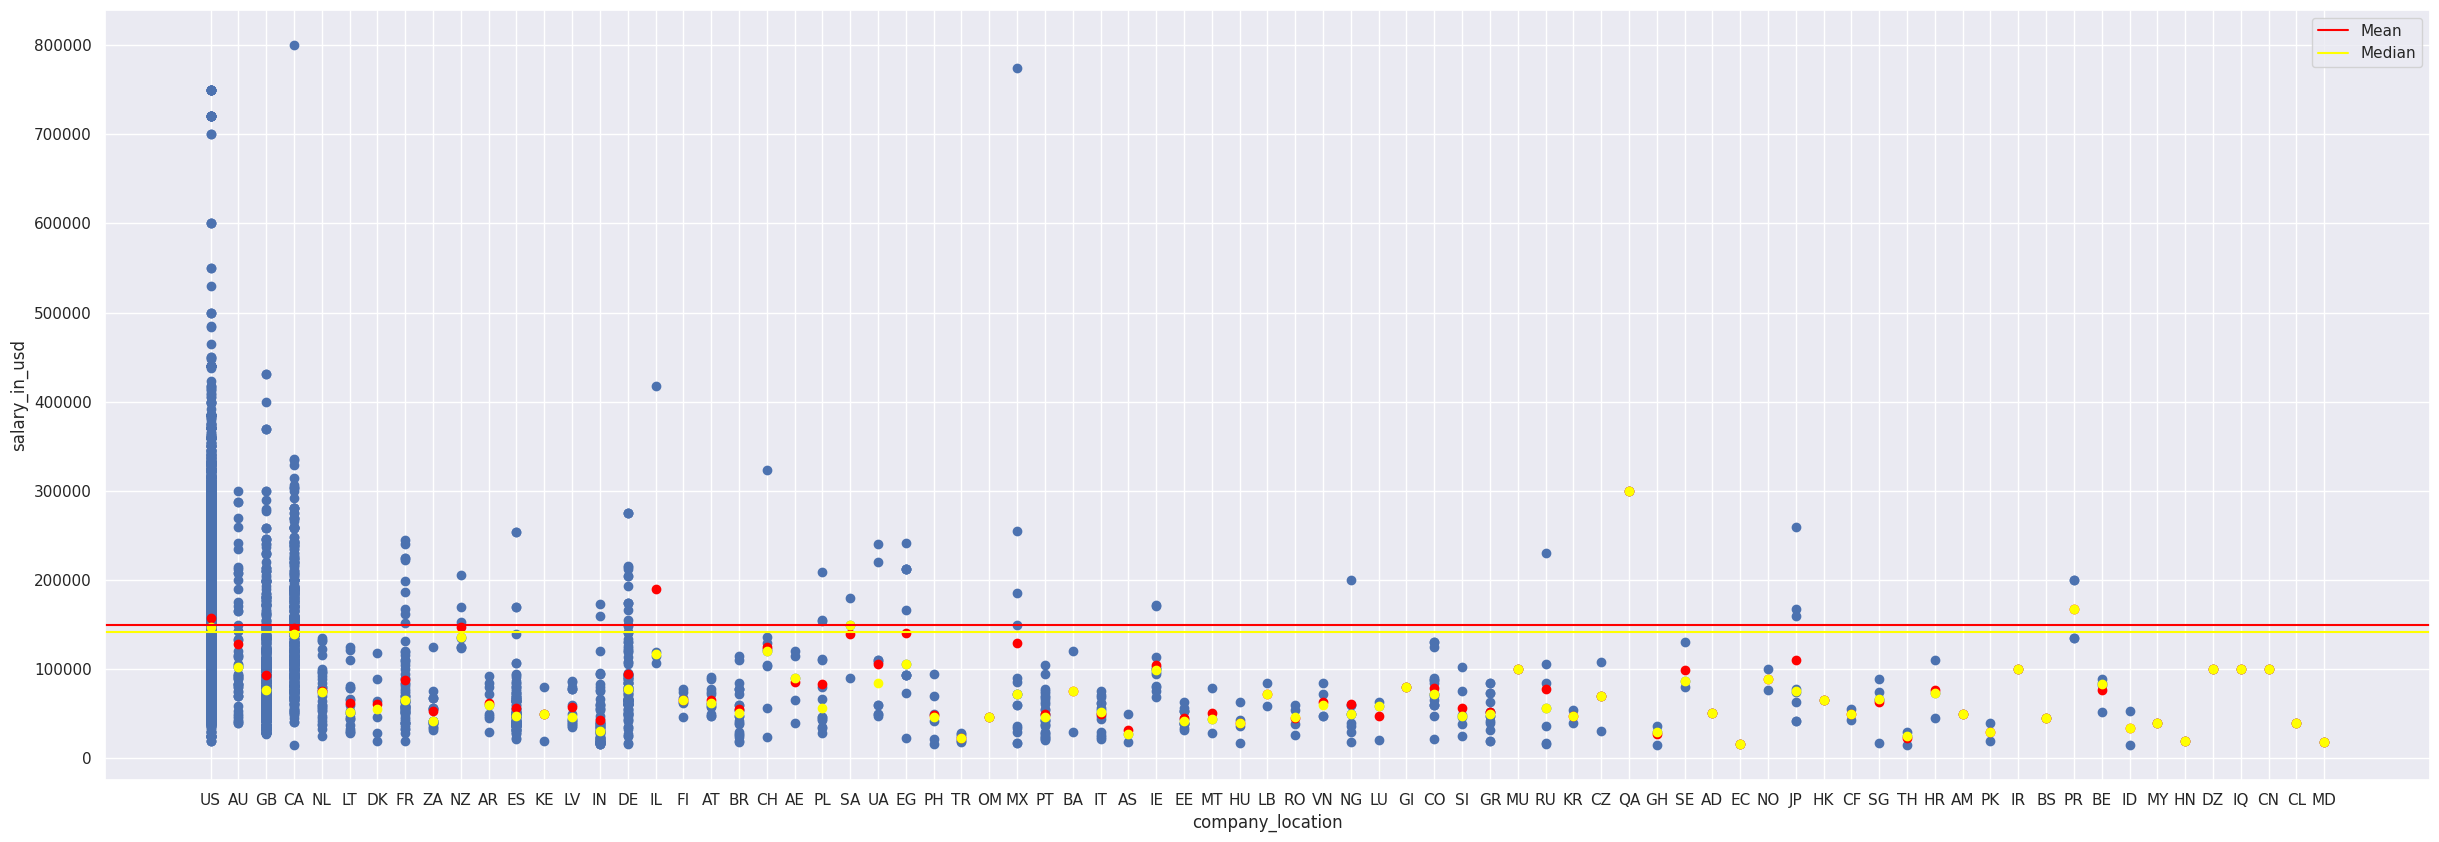

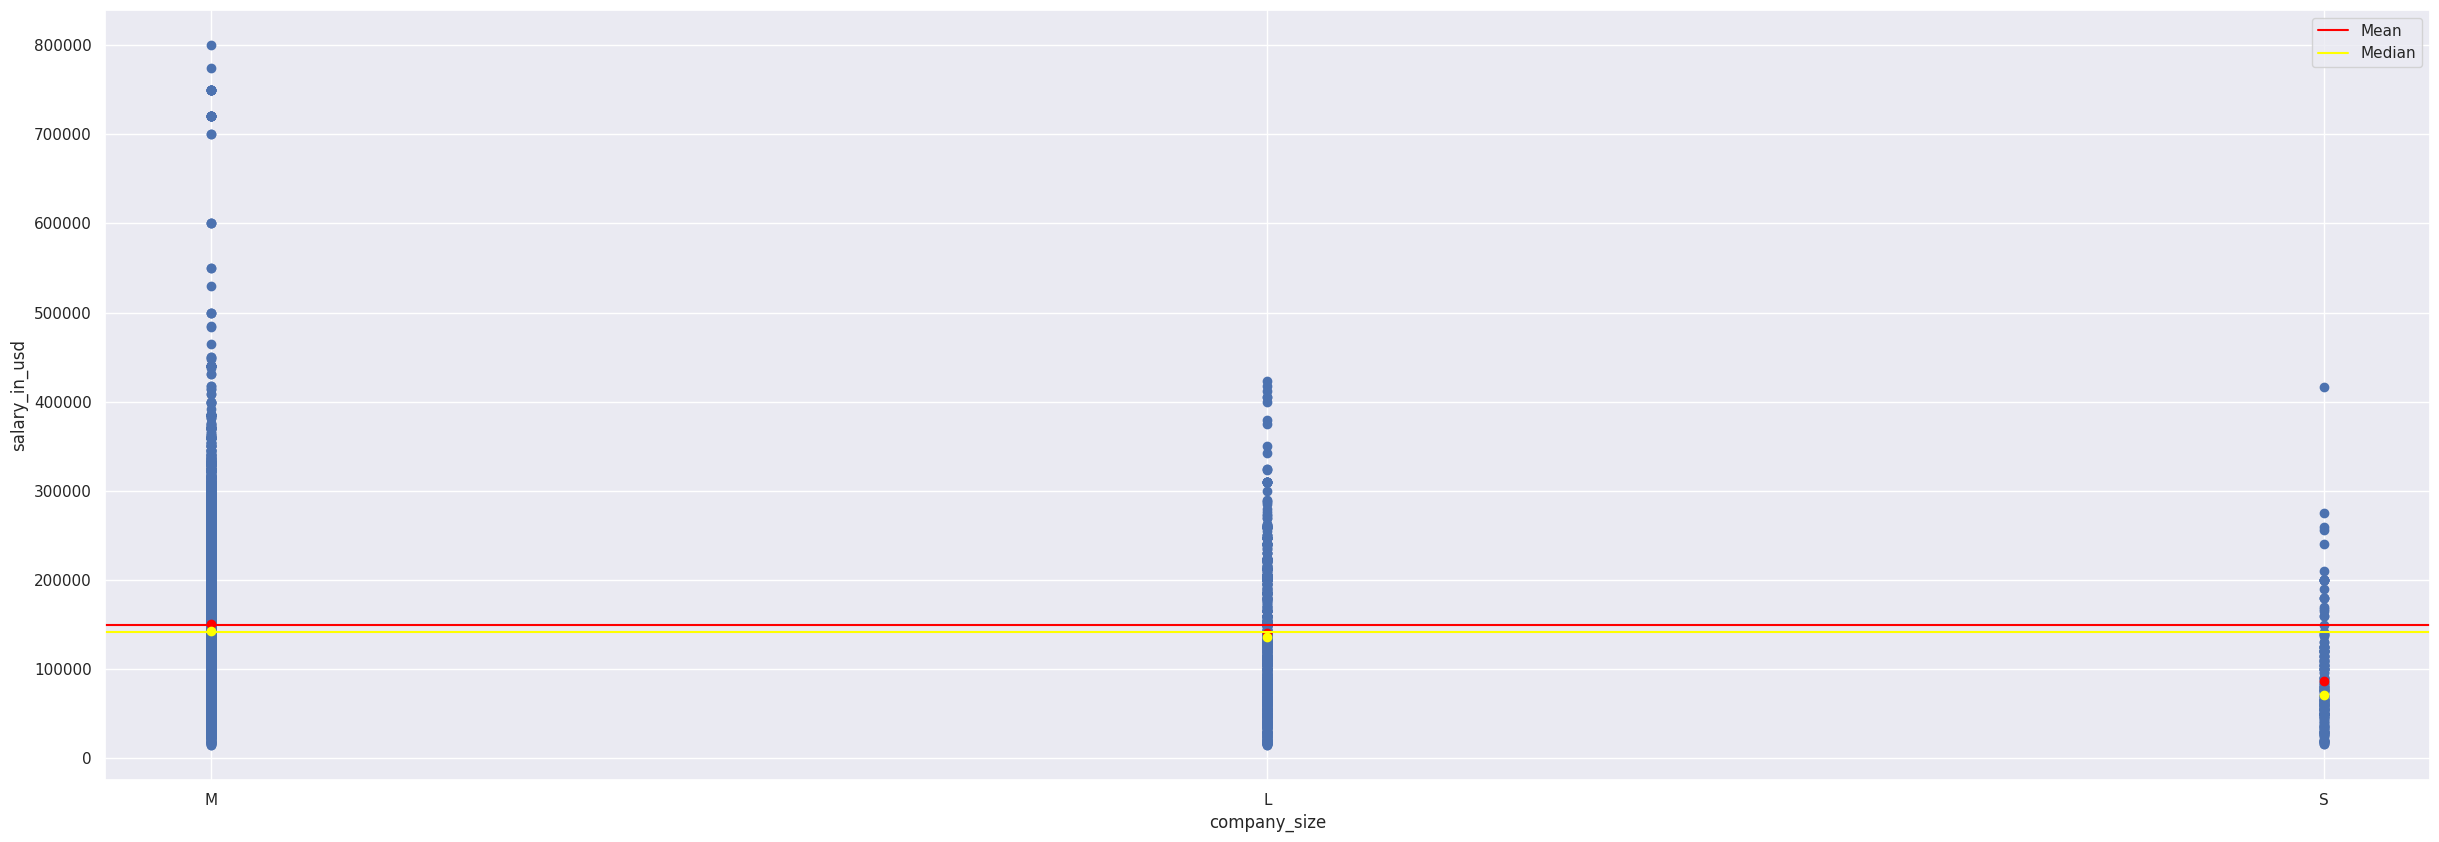

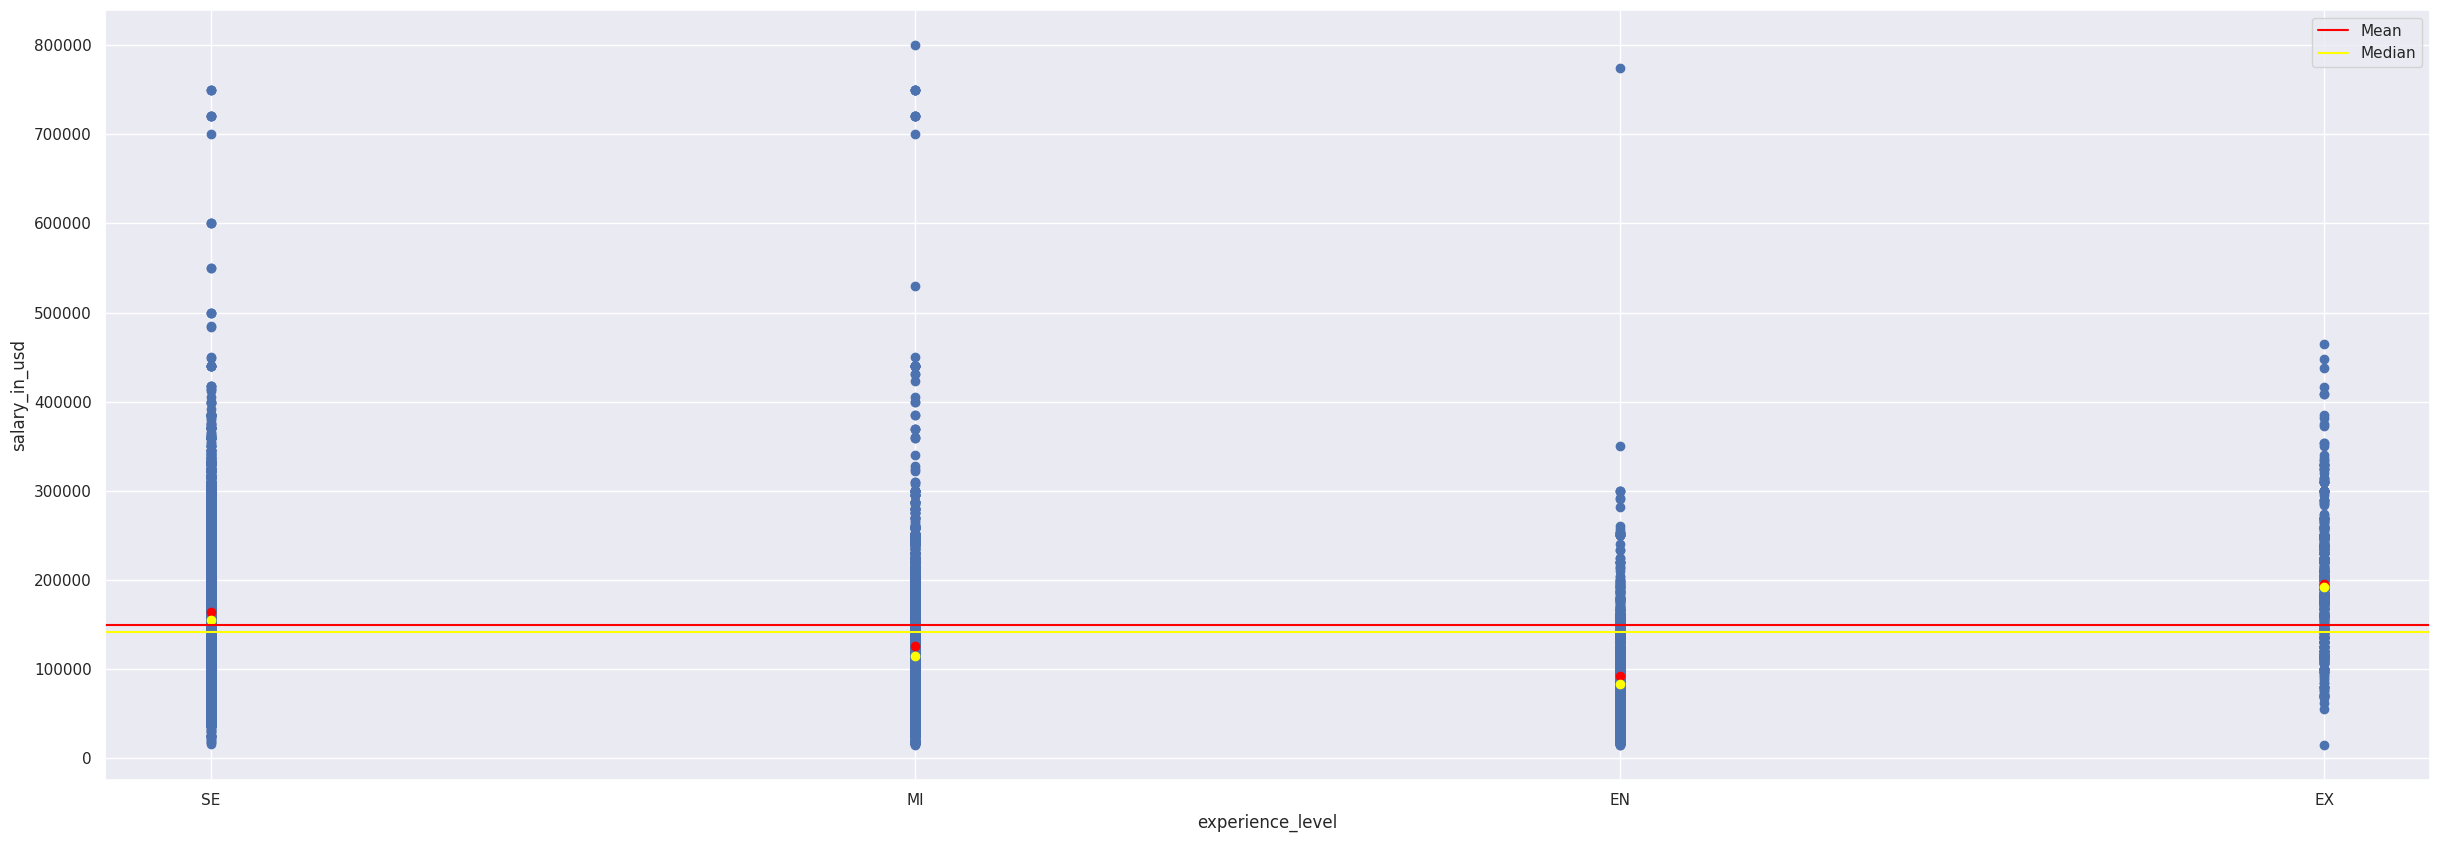

In [ ]:
#plot graph of correlation between employee_residence and salary_in_usd
def barplot(df,categoricalVariable,continuosVariable="salary_in_usd",name=None):
  plt.figure(figsize=(30,10))
  meanmedian = df.groupby(categoricalVariable)[continuosVariable]
  meann = meanmedian.mean()
  mediann = meanmedian.median()
  plt.scatter(df[categoricalVariable], df[continuosVariable])
  plt.axhline(df[continuosVariable].mean(),color="red",label="Mean")
  plt.axhline(np.median(df[continuosVariable]),color="yellow",label="Median")
  plt.scatter(meann.index,meann,color="red")
  plt.scatter(mediann.index,mediann,color="yellow")
  plt.xlabel(categoricalVariable)
  plt.ylabel(continuosVariable)
  plt.legend()
  if name!=None: plt.savefig(name)
  plt.show()

for i in categoricalVariables: barplot(df,i)
barplot(df,"experience_level","salary_in_usd","correlationWithTheSalary.png")

In [ ]:
#compute mean and std of salary_in_usd for each experience_level
means = df.groupby('experience_level')['salary_in_usd'].mean()
stds = df.groupby('experience_level')['salary_in_usd'].std()

Plotting the graphs with salary_in_usd means and stds for each experience_level.

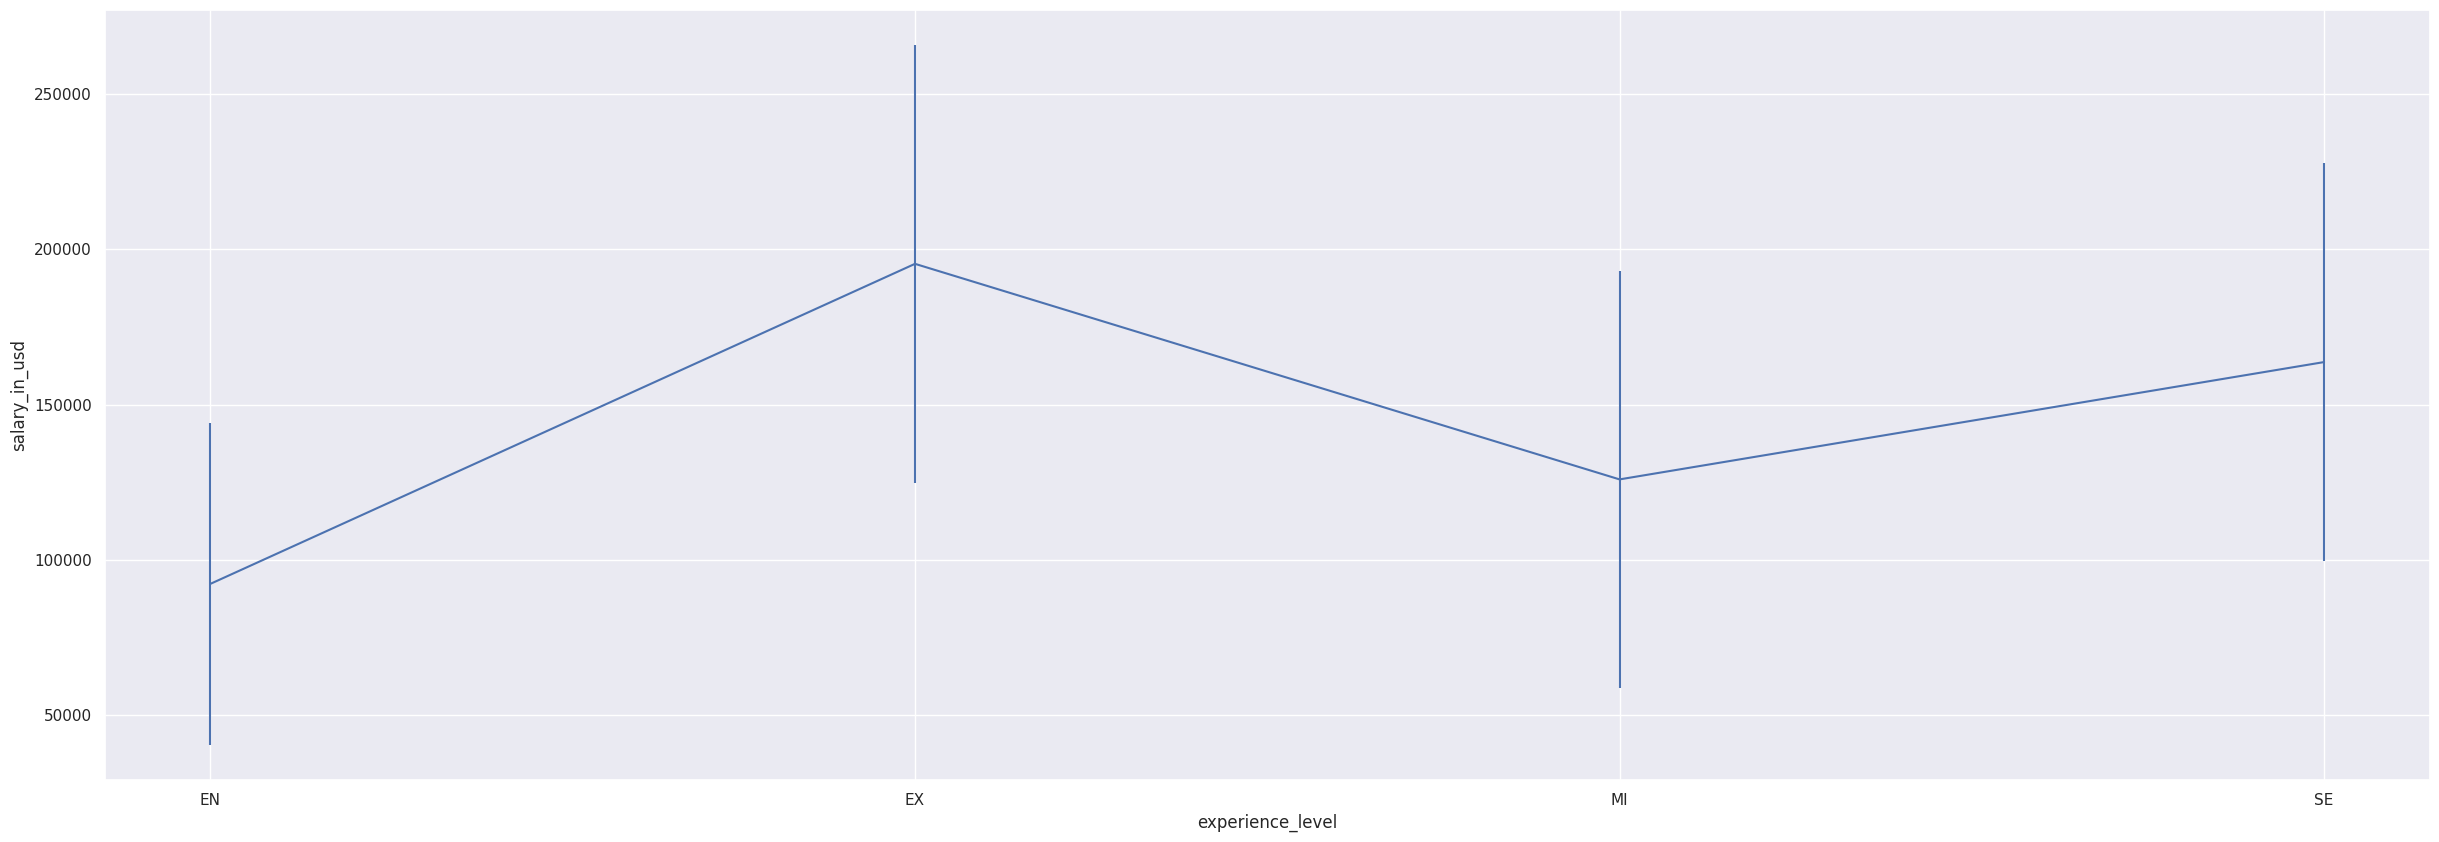

In [ ]:
#plot graphs with means and stds for each experience_level
plt.figure(figsize=(30,10))
plt.errorbar(means.index, means, yerr=stds)

plt.xlabel('experience_level')
plt.ylabel('salary_in_usd')
plt.show()

Plotting box plot of continuos variable depending on the values of each categorical features.

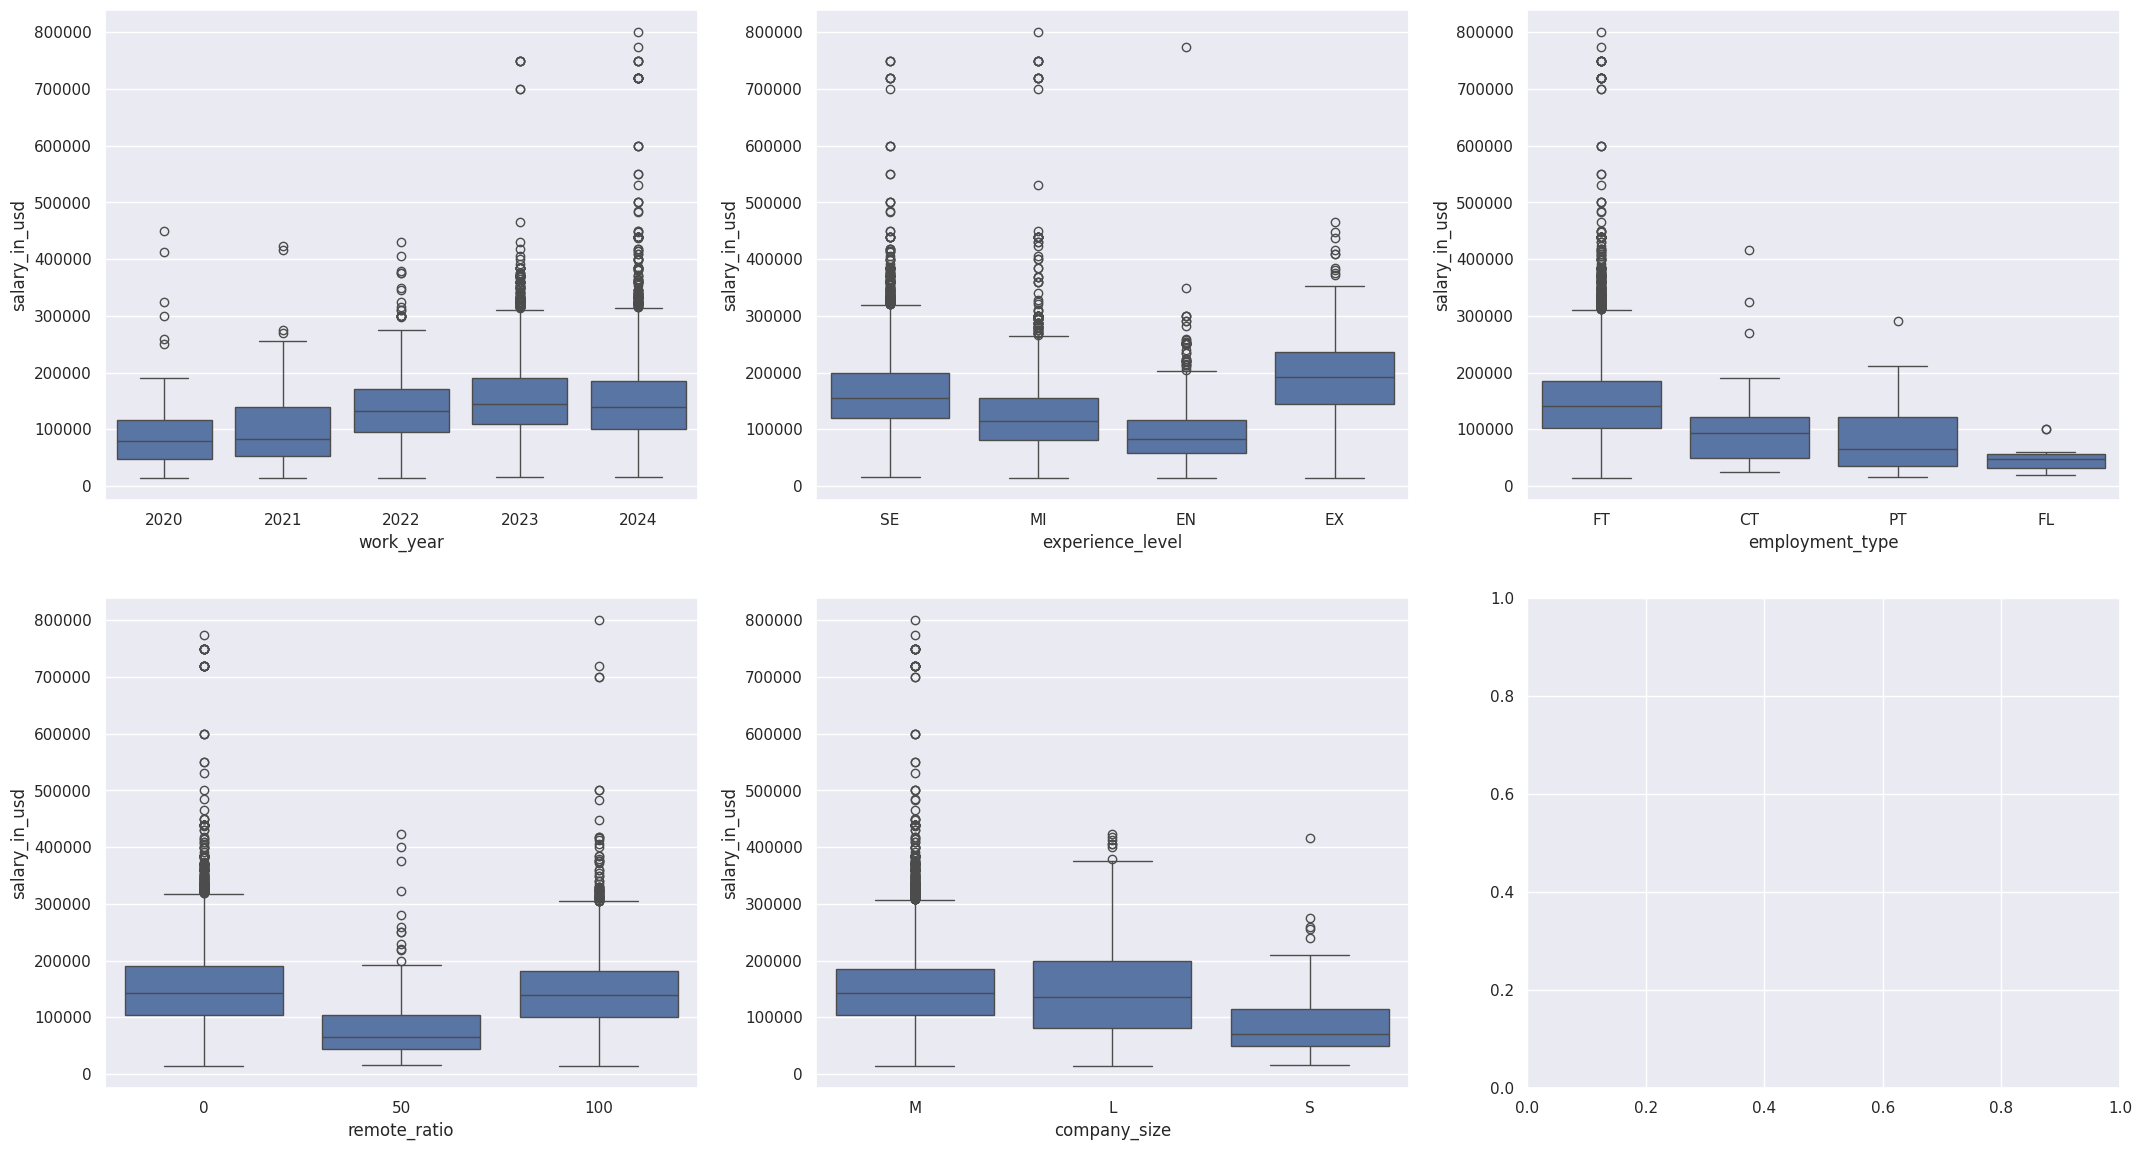

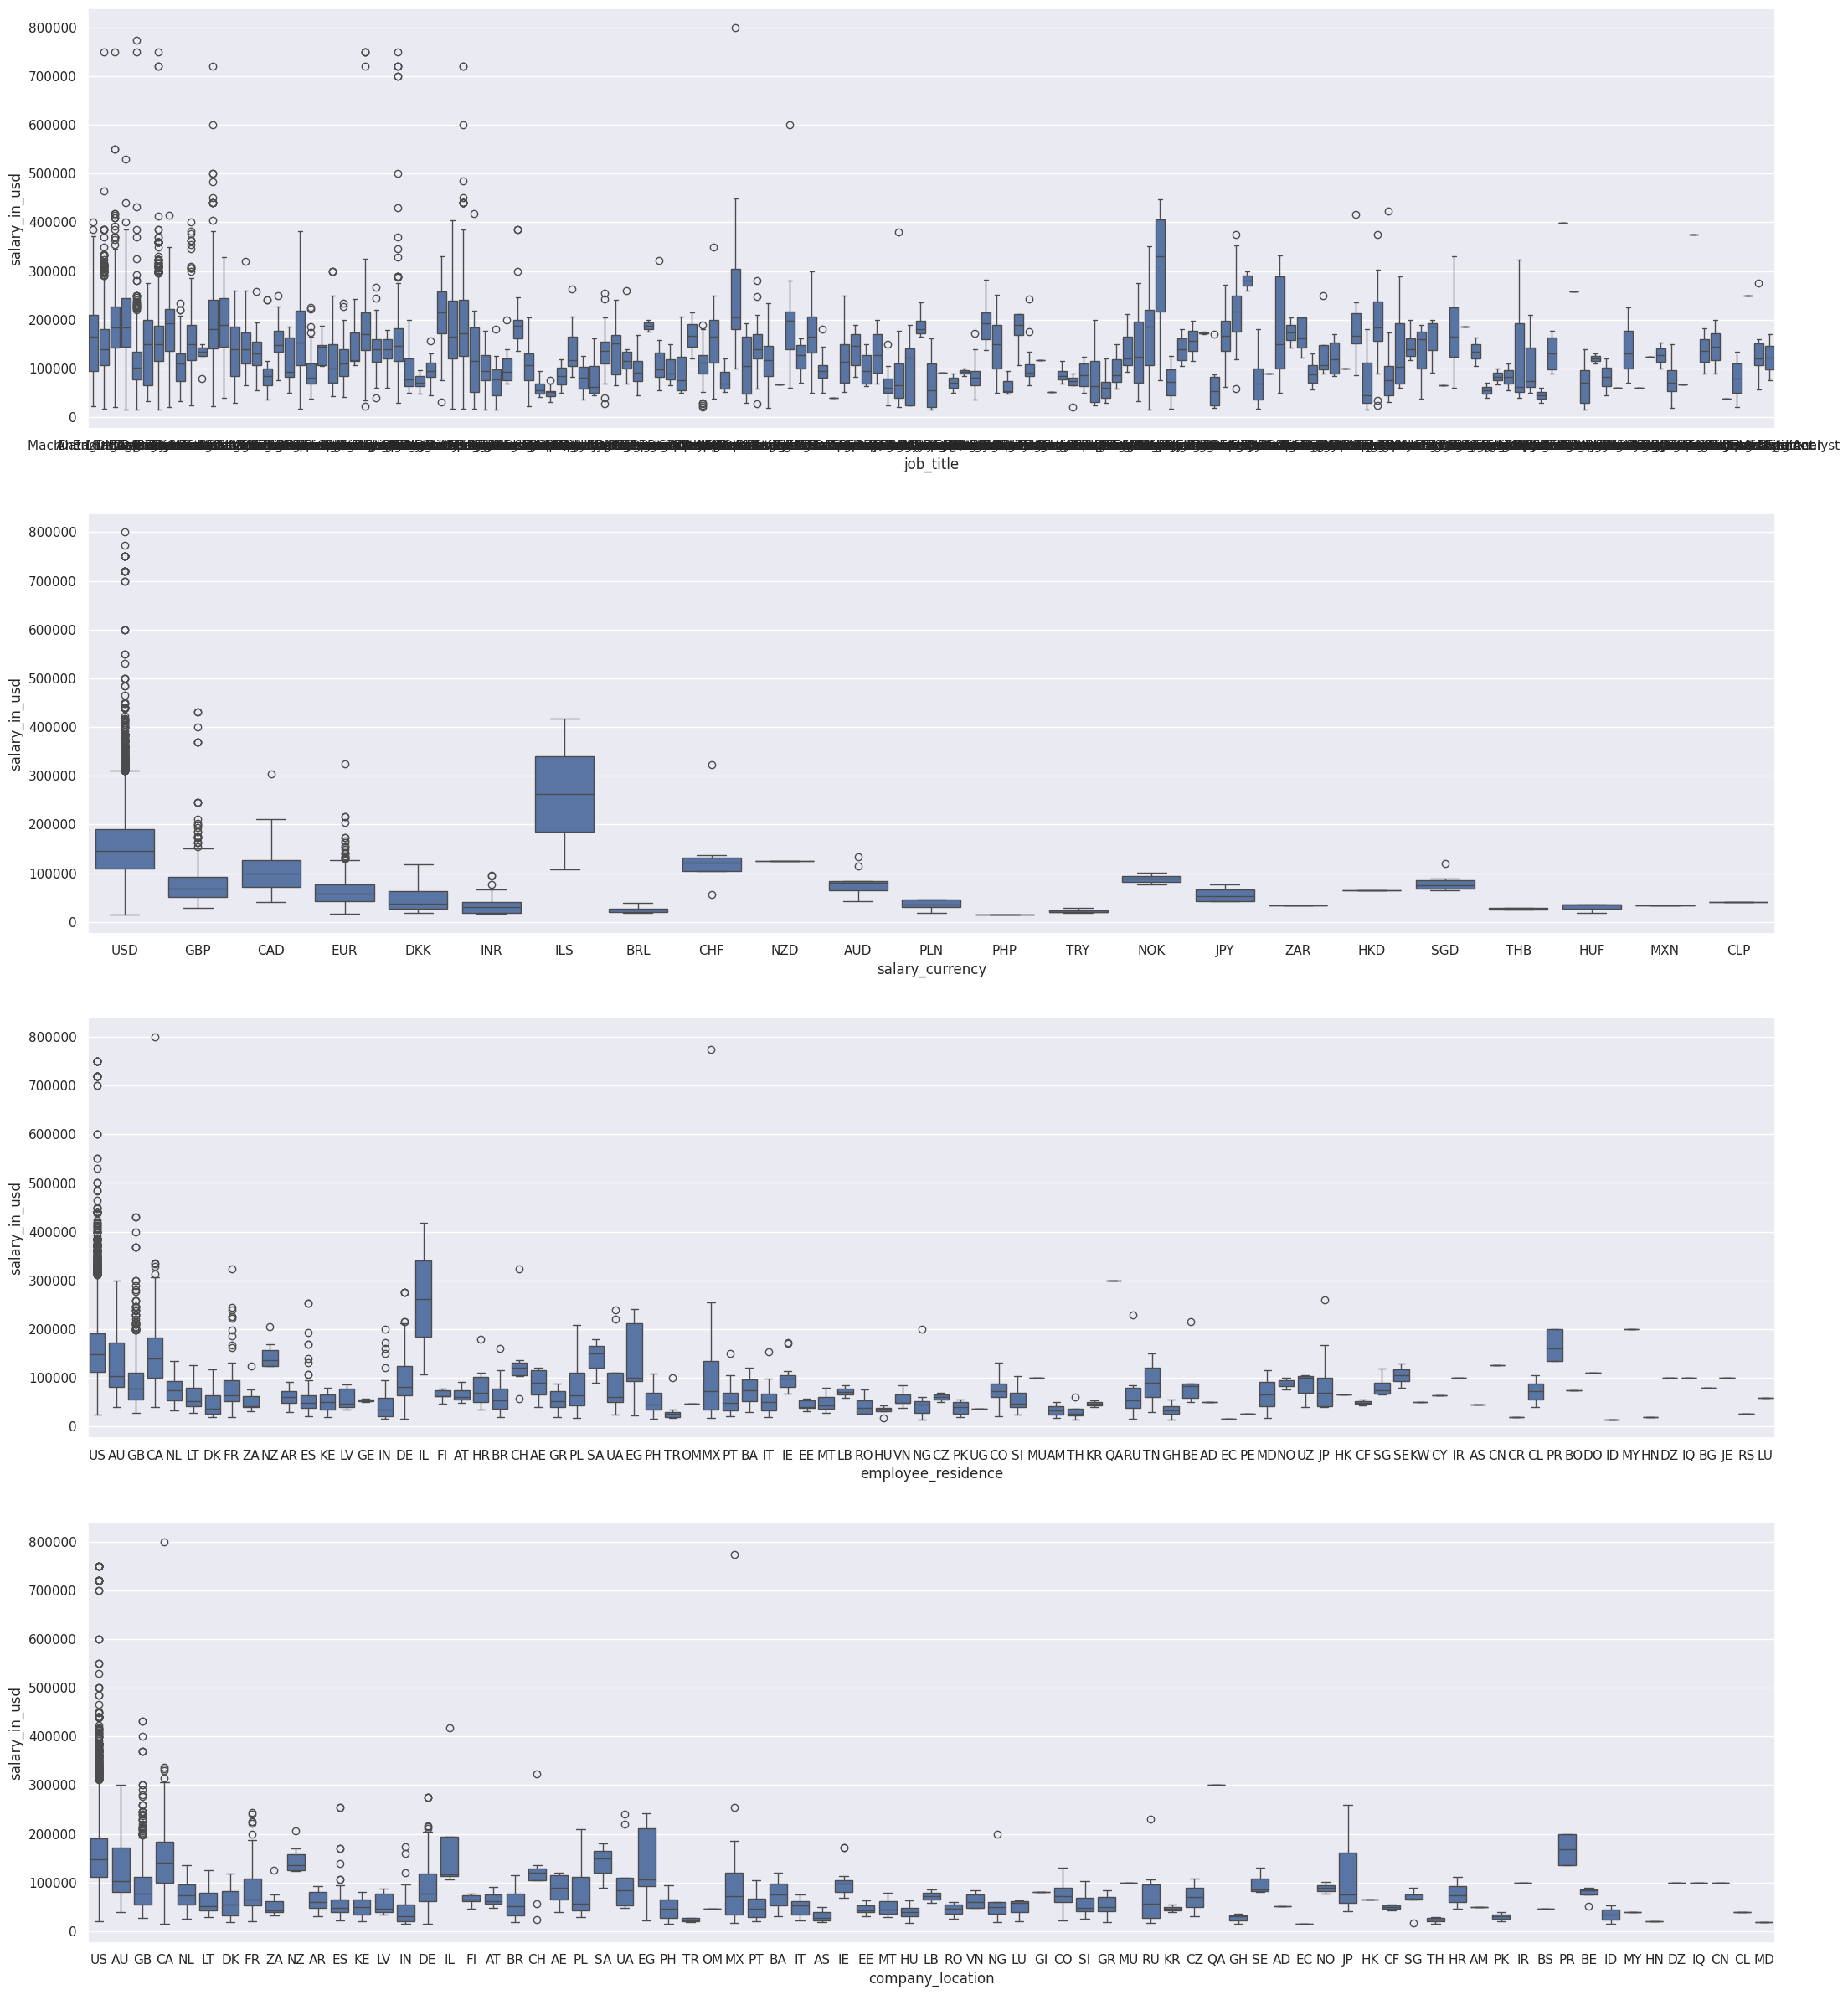

In [ ]:
continuosVariable = continuosVariables[0]
#divide variable depending on the number of values they can have
categoricalVariablesLittle = ["work_year","experience_level","employment_type","remote_ratio","company_size"]
categoricalVariablesHuge = ["job_title","salary_currency","employee_residence","company_location"]

#plot of variable with few values category
fig, axis = plt.subplots(2,3,figsize=(26,14))
for i,i2 in enumerate(categoricalVariablesLittle):
  sns.boxplot(x=df[i2],y=df[continuosVariable],ax=axis[i//3,i%3])

#plot of variable with a lot of values category
fig, axis = plt.subplots(4,1,figsize=(26,30))
for i,i2 in enumerate(categoricalVariablesHuge):
  sns.boxplot(x=df[i2],y=df[continuosVariable],ax=axis[i])

Calculation of the correlation between experience_level feature and each data features using mutual info.

<Axes: >

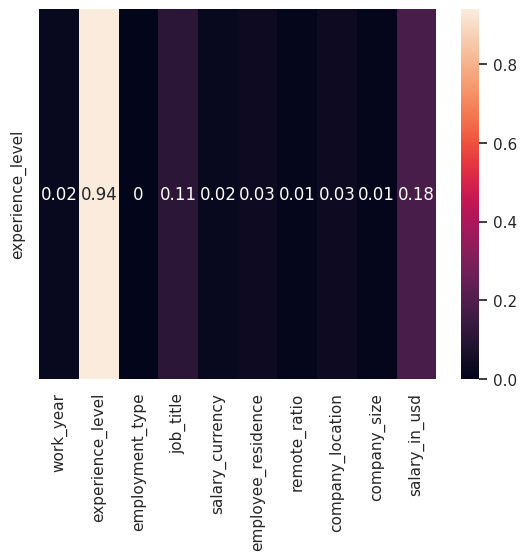

In [ ]:
variablesCorr = [mutual_info_classif(pd.factorize(df[i])[0].reshape(-1,1),df["experience_level"].to_numpy(),discrete_features=i2)[0] for i,i2 in typeVariables.items()]
variablesCorr = [float("{:.2f}".format(i)) for i in variablesCorr]
sns.heatmap([variablesCorr],annot=True,xticklabels=variables,yticklabels=["experience_level"])

Calculation of correlation between experience_level feature and each data features. For the categorical-categorical correlation Cramer's V is used, for categorical-continuos correlation $\eta^2$ is used.

<Axes: >

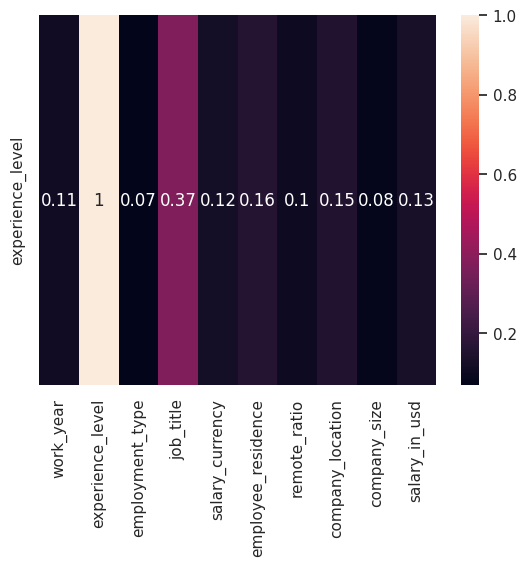

In [ ]:
catCorrelation = []
for i,i2 in typeVariables.items():
  if i2:
    #calculation of Cramer's V
    tablea = pd.crosstab(df["experience_level"],df[i])
    tablechi = stats.chi2_contingency(tablea)[0]
    correlation = np.sqrt((tablechi/tablea.sum().sum())/(min(tablea.shape)-1))
    catCorrelation.append(correlation)
  else:
    #calculation of eta^2
    a = sum([len(i4)*(i4.mean()-df[i].mean())**2 for i3,i4 in df.groupby("experience_level")[i]])
    b = ((df[i]-df[i].mean())**2).sum()
    catCorrelation.append(a/b)

catCorrelation = [float("{:.2f}".format(i)) for i in catCorrelation]
sns.heatmap([catCorrelation],annot=True,xticklabels=variables,yticklabels=["experience_level"])

## Task 3: Preparing the Data 📃
Normalization of the data.

Creation of a function to deal in a more efficient way with the use of the data, through the various test.

In [3]:
#this function return a dataset based on the columns and number of samples that are given. Perform noramlizzation of continuous features and one hot encoding for the categorical features
def getData(columns="all",n=None):
  df = pd.read_csv("drive/MyDrive/Copia di Dataset salary 2024.csv")
  df.drop("salary",axis=1,inplace=True)
  #the features:
  #work year
  #experience level
  #employment type
  #job title
  #salary
  #salary currency
  #salary in usd
  #employee residence
  #remote ratio
  #company location
  #company size

  continuosVariables = ["salary_in_usd"]
  categoricalVariables = ["work_year","experience_level","employment_type","remote_ratio","company_size","job_title","salary_currency","employee_residence","company_location"]
  variables = categoricalVariables+continuosVariables
  typeVariables = dict(zip(variables,[True]*len(categoricalVariables)+[False]*len(continuosVariables)))

  yColumn = "experience_level"
  if columns=="all": columns = [i for i in variables if i!="experience_level"]
  xyColumns = columns+[yColumn]
  df.drop([i for i in df.columns if i not in xyColumns],axis=1,inplace=True)

  for i in xyColumns:
    if typeVariables[i]:
      df = pd.concat([df,pd.get_dummies(df[i],prefix=i,drop_first=False)],axis=1)
      df.drop(i,axis=1,inplace=True)
    else:
      df[i] = (df[i]-df[i].mean())/df[i].std()

  if n!=None: df = df[:n]
  x = df.drop([i for i in df.columns if i.startswith(yColumn)],axis=1)
  label = [i for i in df.columns if i.startswith(yColumn)]
  y = np.argmax(np.array(df[label]),axis=1)
  label = [i[len(yColumn)+1:] for i in label]

  return x,y,label,columns,yColumn
getData.columns = ["salary_in_usd","work_year","experience_level","employment_type","remote_ratio","company_size","job_title","salary_currency","employee_residence","company_location"]

## Task 3: Define the SVM 📃

Importing the library that will be used.

In [17]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, roc_curve, roc_auc_score, balanced_accuracy_score, auc
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import RFECV
from sklearn.calibration import CalibratedClassifierCV
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import label_binarize

Looking for the best features using a recursive feature elimination with cross validation approach.

In [ ]:
#get data
x,y,label,xColumns,yColumn = getData(n=9000)

#chose model
model = SVC(kernel="linear")

#chose parameter for the RFECV
selector = RFECV(model,step=1,cv=2)

#run the ranking of the fetures
selector = selector.fit(x,y)

In [ ]:
#get the results
resultsRFECV = pd.DataFrame({"name":selector.feature_names_in_,"rank":selector.ranking_,"variable":[[i for i in xColumns if i2.startswith(i)][0] for i2 in selector.feature_names_in_]}).groupby("variable")["rank"]
resultsRFECV = pd.DataFrame({"Rank mean":resultsRFECV.mean(),"Rank median":resultsRFECV.median()}).sort_values(by="Rank mean")
print(resultsRFECV)

                     Rank mean  Rank median
variable                                   
salary_in_usd         1.000000          1.0
employment_type       2.750000          1.0
job_title            49.116129         13.0
remote_ratio         58.000000         86.0
company_size         66.333333         77.0
salary_currency      70.869565         93.0
employee_residence   76.079545         66.5
company_location     89.766234         66.0
work_year           112.000000         63.0


The four highest ranked features are selected.

## Task 4: Train 📃

Looking for the best parameters using exhaustive search over specified parameters. 1/2

In [ ]:
#get data
x,y,label,xColumns,yColumns = getData(["job_title","salary_in_usd","remote_ratio","employment_type"],4000)

#divide train and test data
xTrain, xTest, yTrain, yTest = train_test_split(x,y)

#choose parameters
parameters1 = [{"kernel":["rbf","poly"],"C":[1,100,2000],"gamma":[0.001,0.01,0.02]},{"kernel":["linear"],"C":[1,1000]}]

#run the search of the parameters
cl1 = GridSearchCV(SVC(),parameters1,scoring="accuracy",n_jobs=-1,verbose=4,cv=3)
cl1.fit(xTrain,yTrain)
result1 = pd.DataFrame(cl1.cv_results_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


In [ ]:
#get results
print(result1.sort_values(by="mean_test_score"))

    mean_fit_time  std_fit_time  mean_score_time  std_score_time  param_C  \
0        0.859209      0.219393         1.028417        0.134486        1   
1        0.939267      0.031920         0.344831        0.054800        1   
3        0.559474      0.035377         0.217932        0.021730        1   
5        0.656939      0.015181         0.224007        0.015521        1   
7        0.556095      0.024933         0.197200        0.008777      100   
9        1.044921      0.077681         0.359515        0.002947      100   
13       0.557713      0.008279         0.194993        0.012505     2000   
2        1.065613      0.159234         0.998602        0.223434        1   
4        0.703966      0.010123         0.768849        0.078331        1   
11       0.678800      0.051733         0.196016        0.011381      100   
15       0.949801      0.243296         0.222976        0.033586     2000   
6        0.774098      0.077048         0.690118        0.001944      100   

<Axes: xlabel='param_kernel', ylabel='mean_test_score'>

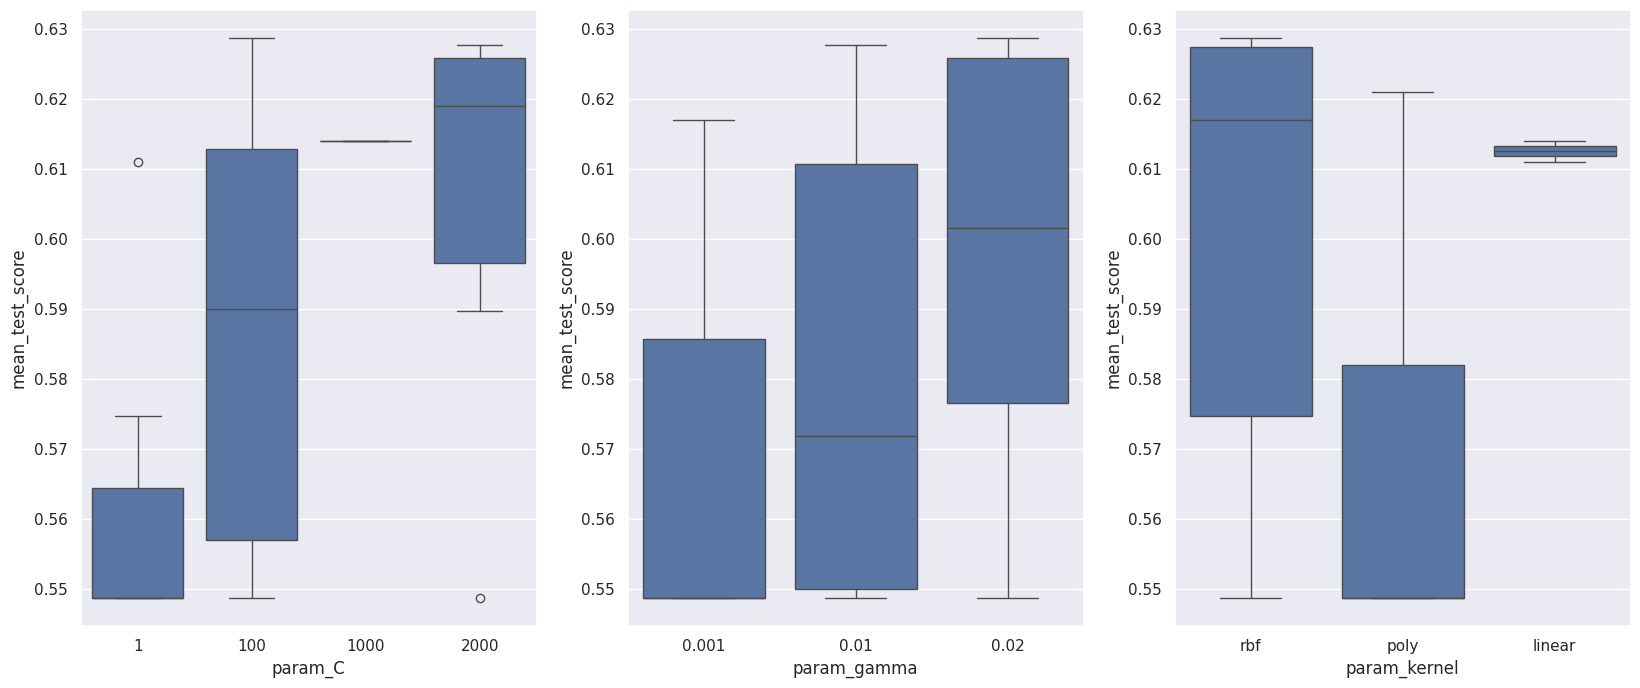

In [ ]:
#plot the test score depending on the various values of the parameters
fig, axes = plt.subplots(1, 3, figsize=(20, 8))
sns.boxplot(x=result1["param_C"],y=result1["mean_test_score"],ax=axes[0])
sns.boxplot(x=result1["param_gamma"],y=result1["mean_test_score"],ax=axes[1])
sns.boxplot(x=result1["param_kernel"],y=result1["mean_test_score"],ax=axes[2])

<Axes: >

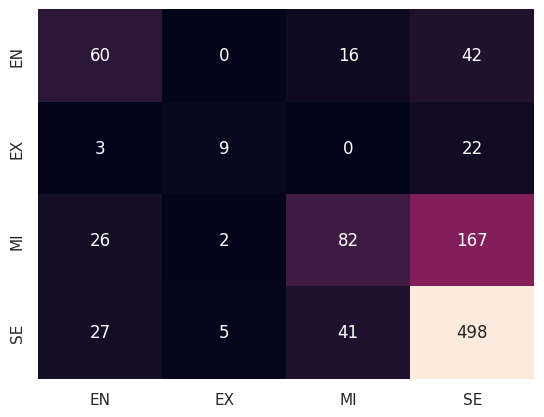

In [ ]:
#run the test using the best model found
y = cl1.best_estimator_.predict(xTest)

#plot results
sns.heatmap(confusion_matrix(yTest,y),annot=True,fmt="d",cbar=False,xticklabels=label,yticklabels=label)

Looking for the best parameters using exhaustive search over specified parameters. 2/2

In [ ]:
#repeat the search with others parameters

#get data
x,y,label,xColumns,yColumns = getData(["job_title","salary_in_usd","remote_ratio","employment_type"],4000)

#divide train and test data
xTrain, xTest, yTrain, yTest = train_test_split(x,y)

#choose parameters
parameters2 = [{"kernel":["rbf"],"C":[2000,10000,100000],"gamma":[0.02,0.1]},{"kernel":["linear"],"C":[2000,10000,100000]}]

#run the search of the parameters
cl2 = GridSearchCV(SVC(),parameters2,scoring="accuracy",n_jobs=-1,verbose=4,cv=3)
cl2.fit(xTrain,yTrain)
result2 = pd.DataFrame(cl2.cv_results_)

Fitting 3 folds for each of 9 candidates, totalling 27 fits


In [ ]:
#get results
print(result2.sort_values(by="mean_test_score"))

   mean_fit_time  std_fit_time  mean_score_time  std_score_time  param_C  \
7    1117.916145     97.573926         0.174334        0.021512    10000   
6     585.387106     21.920699         0.228997        0.074326     2000   
8    2117.592551    222.364212         0.268825        0.079573   100000   
5     226.647582     28.878580         0.652358        0.050627   100000   
2      18.318729      2.780456         0.789124        0.249739    10000   
0      11.042825      1.726875         1.727944        0.533817     2000   
3      46.392568     11.659178         0.615839        0.028677    10000   
4      89.318592     17.469595         0.590492        0.039401   100000   
1      22.441068      7.350463         0.707665        0.115800     2000   

   param_gamma param_kernel                                         params  \
7          NaN       linear               {'C': 10000, 'kernel': 'linear'}   
6          NaN       linear                {'C': 2000, 'kernel': 'linear'}   
8    

In [ ]:
#plot the test score depending on the various values of the parameters
fig, axes = plt.subplots(1, 3, figsize=(20, 8))
sns.boxplot(x=result2["param_C"],y=result2["mean_test_score"],ax=axes[0])
sns.boxplot(x=result2["param_gamma"],y=result2["mean_test_score"],ax=axes[1])
sns.boxplot(x=result2["param_kernel"],y=result2["mean_test_score"],ax=axes[2])

<Axes: >

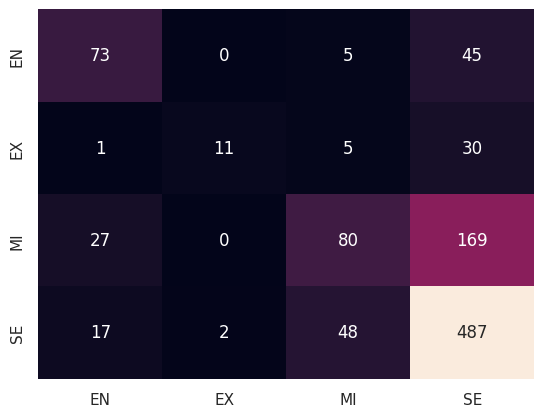

In [ ]:
#run the test using the best model found
y = cl2.best_estimator_.predict(xTest)

#plot results
sns.heatmap(confusion_matrix(yTest,y),annot=True,fmt="d",cbar=False,xticklabels=label,yticklabels=label)

Trying with balanced weight.

In [38]:
#get data
x,y,label,xColumns,yColumns = getData(["job_title","salary_in_usd","remote_ratio","employment_type"])


#divide train and test data
xTrain, xTest, yTrain, yTest = train_test_split(x,y)

#choose model
modelBal1 = SVC(C=2000,kernel="rbf",gamma=0.02,class_weight="balanced")

#train model
modelBal1.fit(xTrain,yTrain)

SVC(C=2000, class_weight='balanced', gamma=0.02)

0.4760522496371553


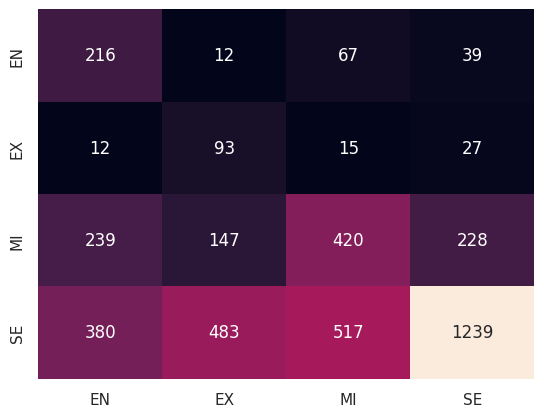

In [39]:
#test model
yBal1 = modelBal1.predict(xTest)

#plot results
sns.heatmap(confusion_matrix(yTest,yBal1),annot=True,fmt="d",cbar=False,xticklabels=label,yticklabels=label)
print(sum(yBal1==yTest)/len(yBal1))

Trying with a Over Sampling Technique.

In [ ]:
#get data
x,y,label,xColumns,yColumns = getData(["job_title","salary_in_usd","remote_ratio","employment_type"])

#over sample using SMOTE
smote = SMOTE(random_state=0)
x,y = smote.fit_resample(x,y)

#divide train and test data
xTrain, xTest, yTrain, yTest = train_test_split(x,y)

#choose model
modelSMOTE1 = SVC(C=2000,kernel="rbf",gamma=0.02)

#train model
modelSMOTE1.fit(xTrain,yTrain)

SVC(C=2000, gamma=0.02)

0.6079662605435802


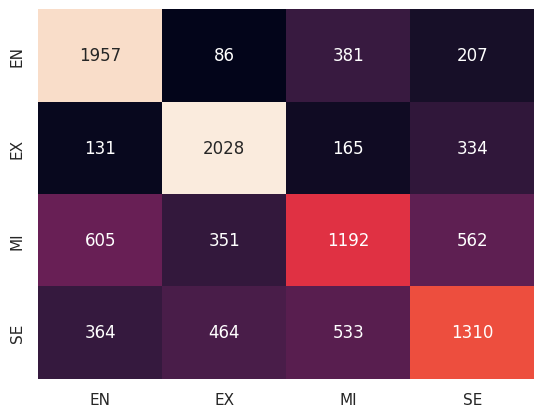

In [ ]:
#test model
ySMOTE1 = modelSMOTE1.predict(xTest)

#plot results
sns.heatmap(confusion_matrix(yTest,ySMOTE1),annot=True,fmt="d",cbar=False,xticklabels=label,yticklabels=label)
print(sum(ySMOTE1==yTest)/len(ySMOTE1))

Trying with a Under Sampling Technique.

In [ ]:
#get data
x,y,label,xColumns,yColumns = getData(["job_title","salary_in_usd","remote_ratio","employment_type"])

#under sample using RandomUnderSampler
smote = RandomUnderSampler(random_state=0)
x,y = smote.fit_resample(x,y)

#divide train and test data
xTrain, xTest, yTrain, yTest = train_test_split(x,y)

#choose model
modelRUS = SVC(C=2000,kernel="rbf",gamma=0.02)

#train model
modelRUS.fit(xTrain,yTrain)

SVC(C=2000, gamma=0.02)

0.5369261477045908


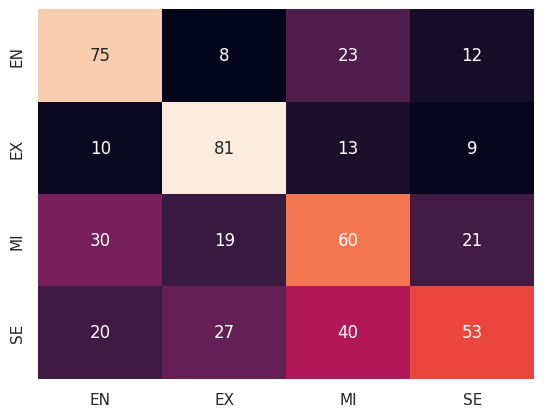

In [ ]:
#test model
yRUS = modelRUS.predict(xTest)

#plot results
sns.heatmap(confusion_matrix(yTest,yRUS),annot=True,fmt="d",cbar=False,xticklabels=label,yticklabels=label)
print(sum(yRUS==yTest)/len(yRUS))

Looking for the best parameters using Over Sampling. This seems the most effective choice in order to build the more precise model.

In [ ]:
#get data
x,y,label,xColumns,yColumns = getData(["job_title","salary_in_usd","remote_ratio","employment_type","company_size"], 4000)

#over sample using SMOTE
smote = SMOTE(random_state=0)
x,y = smote.fit_resample(x,y)

#divide train and test data
xTrain, xTest, yTrain, yTest = train_test_split(x,y)

#choose parameters
parametersOs1 = [{"kernel":["rbf"],"C":[2000,10000],"gamma":[0.001,0.02]},{"kernel":["linear"],"C":[1000,10000]}]

#run the search of the parametrs
clOs1 = GridSearchCV(SVC(),parametersOs1,scoring="accuracy",n_jobs=-1,verbose=4,cv=2)
clOs1.fit(xTrain,yTrain)
resultOs1 = pd.DataFrame(clOs1.cv_results_)

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [ ]:
#get results
print(resultOs1.sort_values(by="mean_test_score"))

   mean_fit_time  std_fit_time  mean_score_time  std_score_time  param_C  \
5     628.859735      7.047450         0.935236        0.427383    10000   
4     239.288364     31.677422         1.074067        0.336927     1000   
0       2.437683      0.183343         3.734893        0.778085     2000   
2       3.268724      0.192780         3.638422        0.988042    10000   
1       7.034481      0.251442         2.993546        0.004020     2000   
3      17.468393      2.525635         3.385602        0.552186    10000   

   param_gamma param_kernel                                         params  \
5          NaN       linear               {'C': 10000, 'kernel': 'linear'}   
4          NaN       linear                {'C': 1000, 'kernel': 'linear'}   
0        0.001          rbf   {'C': 2000, 'gamma': 0.001, 'kernel': 'rbf'}   
2        0.001          rbf  {'C': 10000, 'gamma': 0.001, 'kernel': 'rbf'}   
1        0.020          rbf    {'C': 2000, 'gamma': 0.02, 'kernel': 'rbf'}   

0.6806495263870095


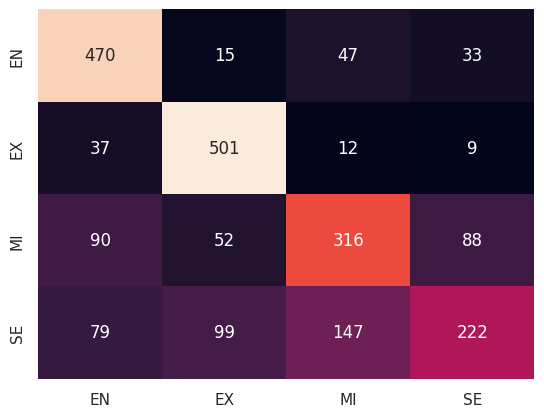

In [ ]:
#test model
yOs1 = clOs1.best_estimator_.predict(xTest)

#plot results
sns.heatmap(confusion_matrix(yTest,yOs1),annot=True,fmt="d",cbar=False,xticklabels=label,yticklabels=label)
print(sum(yOs1==yTest)/len(yOs1))

# The best classificator.

Using the results of the previous search we build the best model found.

In [28]:
#get data
x,y,label,xColumns,yColumns = getData(["job_title","salary_in_usd","remote_ratio","employment_type"])

#over sample using SMOTE
smote = SMOTE(random_state=0)
x,y = smote.fit_resample(x,y)

#divide train and test test
xTrain, xTest, yTrain, yTest = train_test_split(x,y)

#choose the parameters
C = 10000
kernel = "rbf"
gamma = 0.02

#build model
model = SVC(C=C,kernel=kernel,gamma=gamma)

Train model.

In [29]:
model.fit(xTrain,yTrain)

SVC(C=10000, gamma=0.02)

Test model.

In [30]:
yP = model.predict(xTest)

Get measuraments.

In [31]:
accuracy = accuracy_score(yTest,yP)
precision = precision_score(yTest,yP,average="macro")
recall = recall_score(yTest,yP,average="macro")
f1Score = f1_score(yTest,yP,average="macro")
balancedAccuracy = balanced_accuracy_score(yTest,yP)
mccScore = matthews_corrcoef(yTest,yP)

print("Accuracy: {}".format(accuracy))
print("Precision: {}".format(precision))
print("recall: {}".format(recall))
print("f1 Score: {}".format(f1Score))
print("Balanced accuracy: {}".format(balancedAccuracy))
print("Metthews correlation coefficient: {}".format(mccScore))

Accuracy: 0.6233364573570759
Precision: 0.6153232140735873
recall: 0.6242177148651682
f1 Score: 0.6167353036186584
Balanced accuracy: 0.6242177148651682
Metthews correlation coefficient: 0.49956869043647206


Train model with probabilities.

In [35]:
modelP = CalibratedClassifierCV(model,cv=2,ensemble=False)
modelP.fit(xTrain,yTrain)

CalibratedClassifierCV(cv=2, ensemble=False, estimator=SVC(C=10000, gamma=0.02))

Test model with probabilities.

In [36]:
yPp = modelP.predict_proba(xTest)

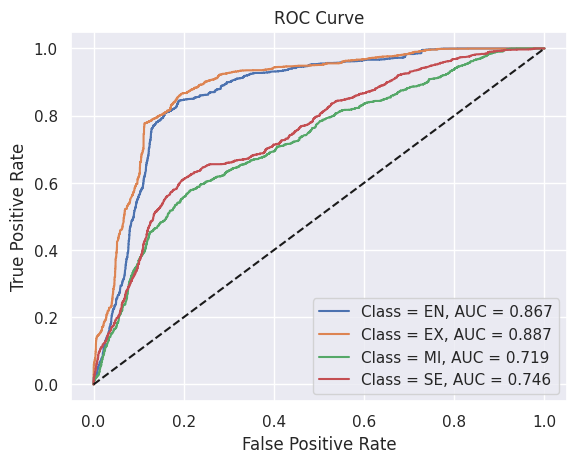

In [37]:
aucScore = roc_auc_score(yTest,yPp,multi_class="ovo")

#plot ROC curve
yTestBin = label_binarize(yTest, classes=modelP.classes_)

for i in range(len(modelP.classes_)):
  fp, tp, tr = roc_curve(yTestBin[:,i],yPp[:,i])
  rocAuc = auc(fp,tp)
  plt.plot(fp, tp, label="Class = {}, AUC = {:.3f}".format(label[modelP.classes_[i]],rocAuc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

<Axes: >

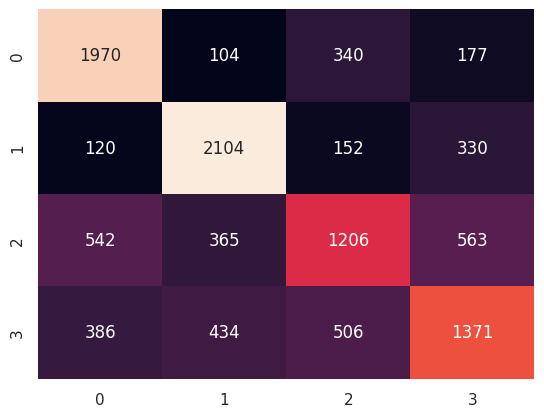

In [32]:
#plot results
sns.heatmap(confusion_matrix(yTest,yP),annot=True,fmt="d",cbar=False)